# Data Visualization in Python
### QLS-MiCM · Code to Manuscript Bootcamp · Day 1

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZahraTavakkol/Data-Visualization-in-Python/blob/main/Exercises/solutions/DataVisualizationInPython_solutions.ipynb)

In this session we go from a table of RNA-seq counts to a **publication-ready, multi-panel figure** using
[Matplotlib](https://matplotlib.org/) and [Seaborn](https://seaborn.pydata.org/).

| Module | Topic | Time |
|---|---|---|
| 0 | Setup & the dataset | 10 min |
| 1 | Anatomy of a Matplotlib figure | 15 min |
| 2 | Seaborn, tidy data & distributions | 20 min |
| 3 | Relationships: scatter, MA & volcano plots | 20 min |
| 4 | Heatmaps & clustered heatmaps | 15 min |
| 5 | Dimensionality reduction: PCA, t-SNE, UMAP | 15 min |
| 6 | Multi-panel figures & high-resolution export | 20 min |
| – | Wrap-up: publication-figure checklist | 5 min |

Cells and exercises marked *(optional)* can be skipped if time is short and explored after the workshop.

Each module ends with a short **✏️ Exercise**. **This is the solutions version.**
Solutions are in [`Exercises/solutions/`](https://github.com/QLS-MiCM/Fall-2026-Bootcamp-Data-Visualization-in-Python/blob/tree/main/Exercises/solutions).

---
## Module 0 – Setup & the dataset

Run the cell below first. If you are on **Google Colab**, it installs the two extra packages we need (`umap-learn`, `adjustText`)
and reads the data directly from GitHub. If you run locally, it reads from `Exercises/data/`.

In [ ]:
import sys, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore", message=".*IProgress.*")   # silence a harmless progress-bar warning

using_colab = "google.colab" in sys.modules   # detected automatically

# Install the two extra packages if they are missing (Colab has everything else)
for pkg, mod in [("umap-learn", "umap"), ("adjustText", "adjustText")]:
    try:
        __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

if using_colab:
    DATA = "https://raw.githubusercontent.com/QLS-MiCM/Fall-2026-Bootcamp-Data-Visualization-in-Python/main/Exercises/data/"
else:
    DATA = "../data/"             # path relative to this notebook

FIGS = Path("figures")          # exported figures go here
FIGS.mkdir(exist_ok=True)
print("Reading data from:", DATA)

Reading data from: ../data/


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%config InlineBackend.figure_format = "retina"   # sharper plots in the notebook

print("matplotlib", plt.matplotlib.__version__, "| seaborn", sns.__version__)

matplotlib 3.11.2 | seaborn 0.13.2


### The dataset: SARS-CoV-2 infection of the human eye (GEO [GSE164073](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE164073))

Eriksen *et al.* (2021, *Cell Stem Cell*) infected post-mortem human **cornea, limbus and sclera** with SARS-CoV-2
(**CoV2**) or a **mock** control and measured gene expression with bulk RNA-seq: **3 tissues × 2 conditions × 3 donors = 18 samples**.
It is the same dataset used in the QLS-MiCM *Differential Gene Expression* workshop and in **Day 2 (R / ggplot2)**.

| File | What it contains |
|---|---|
| `sample_metadata.csv` | one row per sample: `sample`, `tissue`, `condition` |
| `GSE164073_Eye_count_matrix.tsv` | raw read counts (genes × samples) |
| `log2cpm_filtered.csv` | normalised expression, log2(CPM + 1), lowly-expressed genes removed |
| `de_cornea_CoV2_vs_mock.csv` | differential expression results in cornea (CoV2 vs mock, PyDESeq2) |

We will not cover *how* these were computed (see `Exercises/data_scripts/prepare_data.py`) – today is about **showing** data.

In [3]:
meta   = pd.read_csv(DATA + "sample_metadata.csv")
counts = pd.read_csv(DATA + "GSE164073_Eye_count_matrix.tsv", sep="\t", index_col=0)
expr   = pd.read_csv(DATA + "log2cpm_filtered.csv", index_col=0)
de     = pd.read_csv(DATA + "de_cornea_CoV2_vs_mock.csv", index_col=0)

print("counts:", counts.shape, "| expr:", expr.shape, "| DE table:", de.shape)
meta.head()

counts: (27946, 18) | expr: (13422, 18) | DE table: (13374, 5)


,sample,tissue,condition
0,MW1,cornea,mock
1,MW2,cornea,mock
2,MW3,cornea,mock
3,MW4,cornea,CoV2
4,MW5,cornea,CoV2


#### Good practice from the start: one colour scheme for the whole project

Decide **once** which colour means what, and reuse it in every panel (and in R tomorrow!).
We use the [Okabe–Ito](https://jfly.uni-koeln.de/color/) palette, which is colour-blind safe.

In [4]:
TISSUE_COLORS    = {"cornea": "#E69F00", "limbus": "#56B4E9", "sclera": "#009E73"}
CONDITION_COLORS = {"mock": "#999999", "CoV2": "#CC79A7"}
TISSUE_ORDER, CONDITION_ORDER = list(TISSUE_COLORS), list(CONDITION_COLORS)

# A clean, consistent default look for every plot
sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"axes.spines.right": False, "axes.spines.top": False})

---
## Module 1 – Anatomy of a Matplotlib figure

Every Matplotlib plot is made of a **Figure** (the whole canvas) containing one or more **Axes** (an individual plot,
with its own x/y axis, title, labels…). Seaborn draws *on* Matplotlib Axes, so understanding these two objects is
what lets you customise *anything*.

<img src="https://matplotlib.org/stable/_images/sphx_glr_anatomy_001.png" width="420">

There are two ways to write Matplotlib code:

| Implicit (`plt.` "state machine") | Explicit / object-oriented (**recommended**) |
|---|---|
| `plt.plot(x, y)`<br>`plt.title("...")` | `fig, ax = plt.subplots()`<br>`ax.plot(x, y)`<br>`ax.set_title("...")` |
| Quick, but "which plot am I editing?" gets confusing | You always know which Axes you are drawing on → essential for multi-panel figures |

#### Building a figure step by step

In this notebook we build most figures **one step at a time**, so you can see exactly what each function changes.
Jupyter draws a figure automatically only in the cell that *creates* it. In the following cells we modify the same
`fig`/`ax` objects and end the cell with **`fig`** to display the updated figure again.

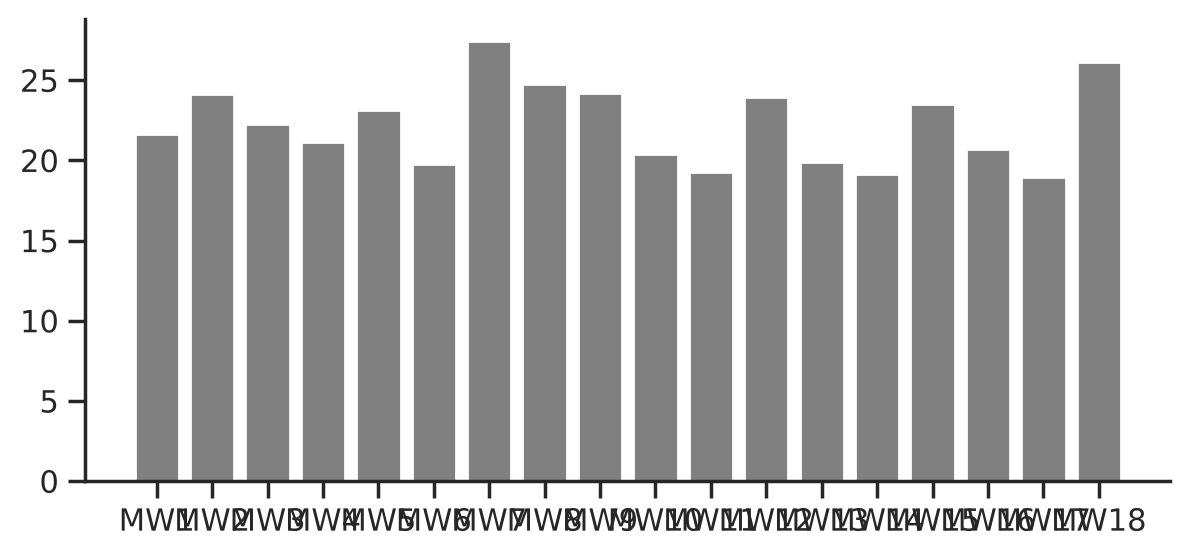

In [5]:
# Step 1 – create an empty Figure with one Axes, and draw the bars
lib_size = counts.sum(axis=0) / 1e6          # library size = total reads per sample, in millions

fig, ax = plt.subplots(figsize=(7, 3))        # figure size in inches (width, height)
ax.bar(lib_size.index, lib_size.values, color="grey")
plt.show()

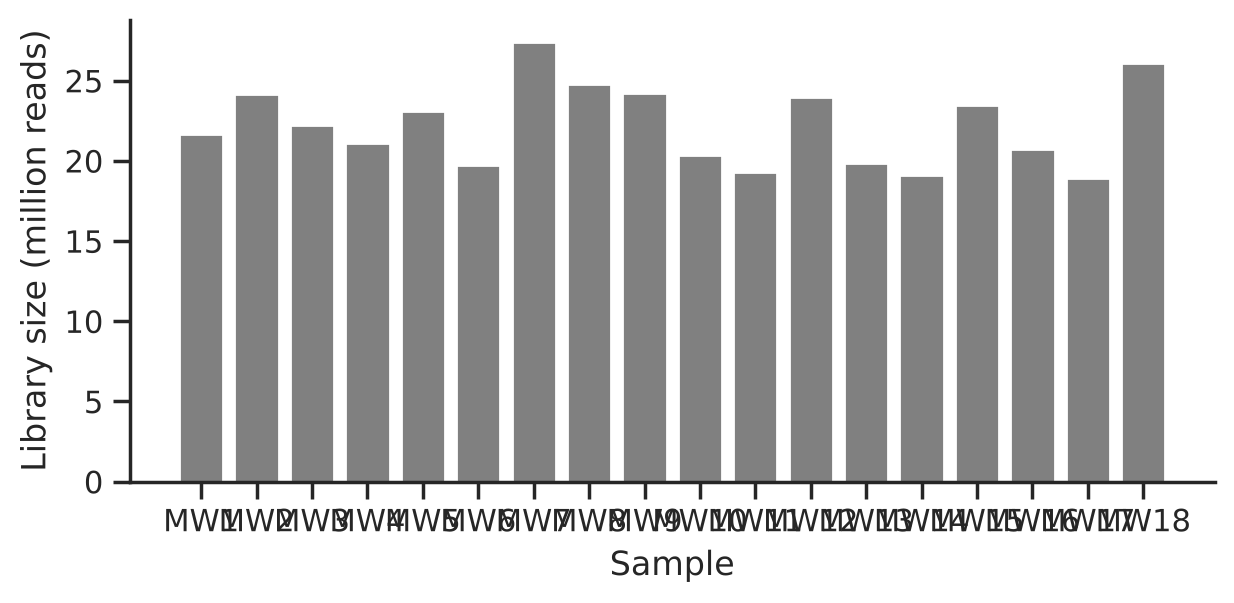

In [6]:
# Step 2 – label the axes (always give units!)
ax.set_xlabel("Sample")
ax.set_ylabel("Library size (million reads)")
fig                                           # display the updated figure

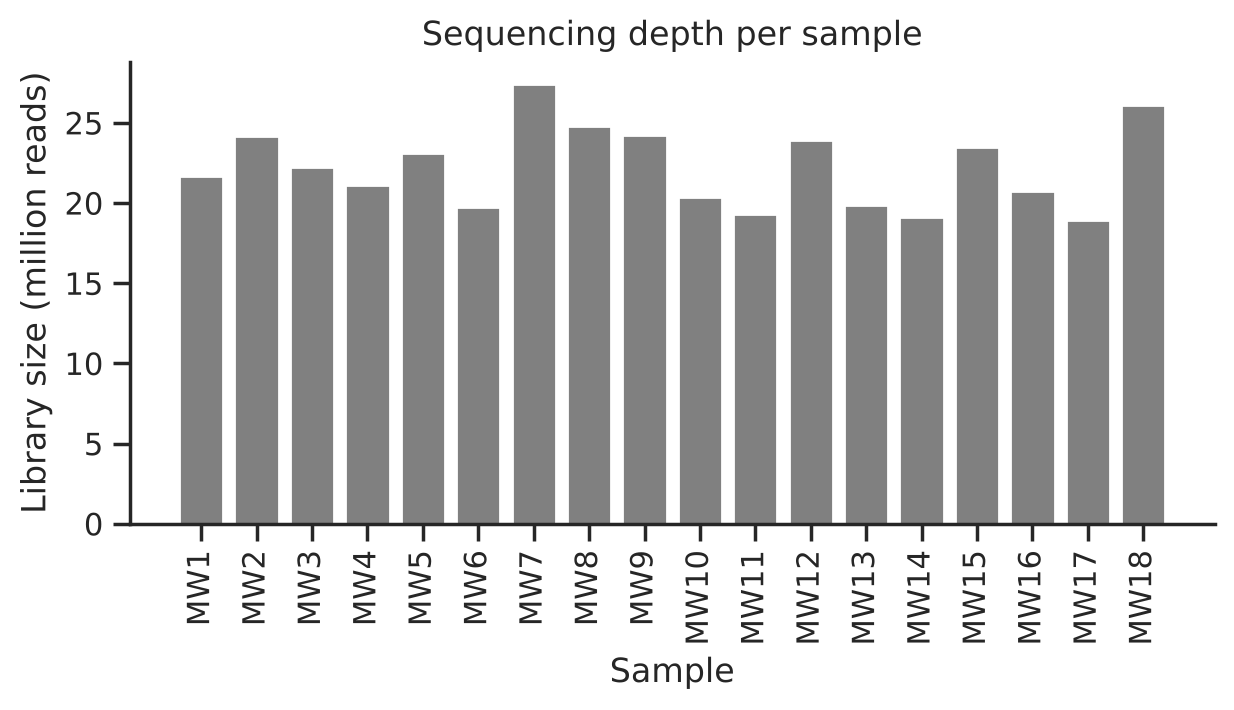

In [7]:
# Step 3 – add a title and rotate the sample names so they don't overlap
ax.set_title("Sequencing depth per sample")
ax.tick_params(axis="x", rotation=90)
fig

**Customising** is just calling more methods on `ax`. Below we colour each bar by tissue and then add a legend.
Notice how we *map* each sample to a colour using the dictionary we defined earlier.

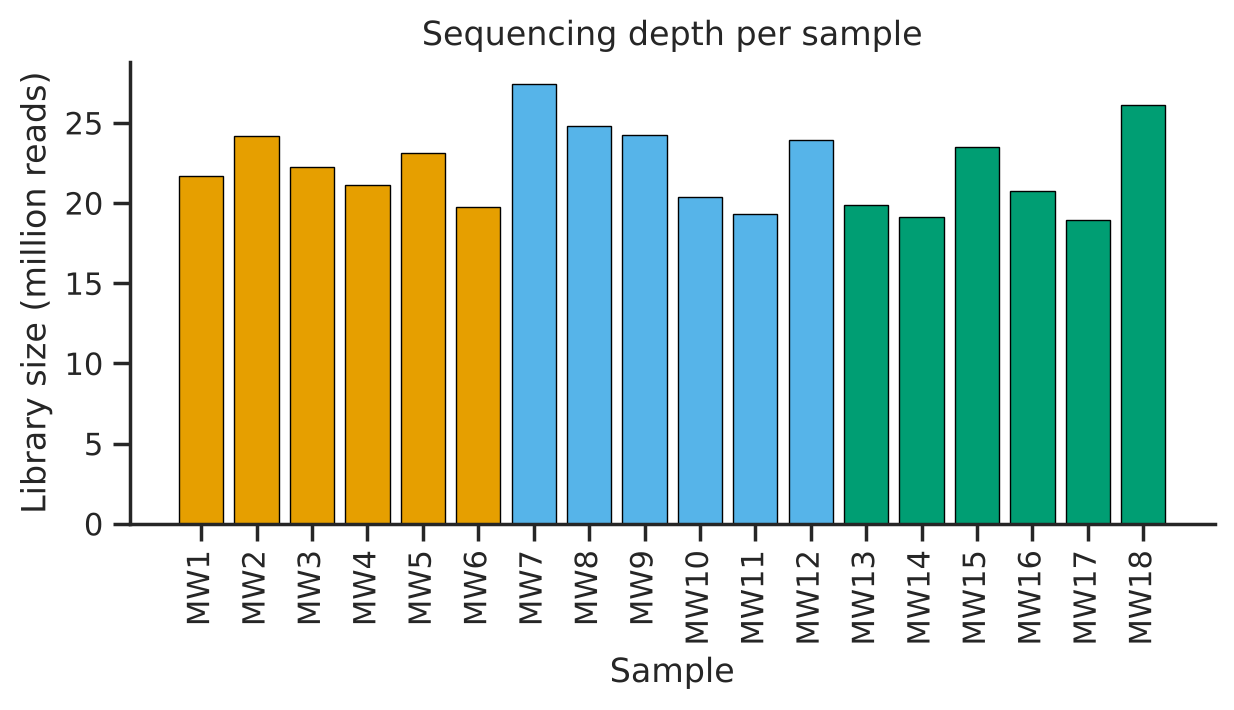

In [8]:
# Step 1 – bars coloured by tissue; ax.set() sets several properties at once
bar_colors = meta["tissue"].map(TISSUE_COLORS)

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(meta["sample"], lib_size[meta["sample"]], color=bar_colors, edgecolor="black", linewidth=0.5)
ax.set(xlabel="Sample", ylabel="Library size (million reads)", title="Sequencing depth per sample")
ax.tick_params(axis="x", rotation=90)
plt.show()

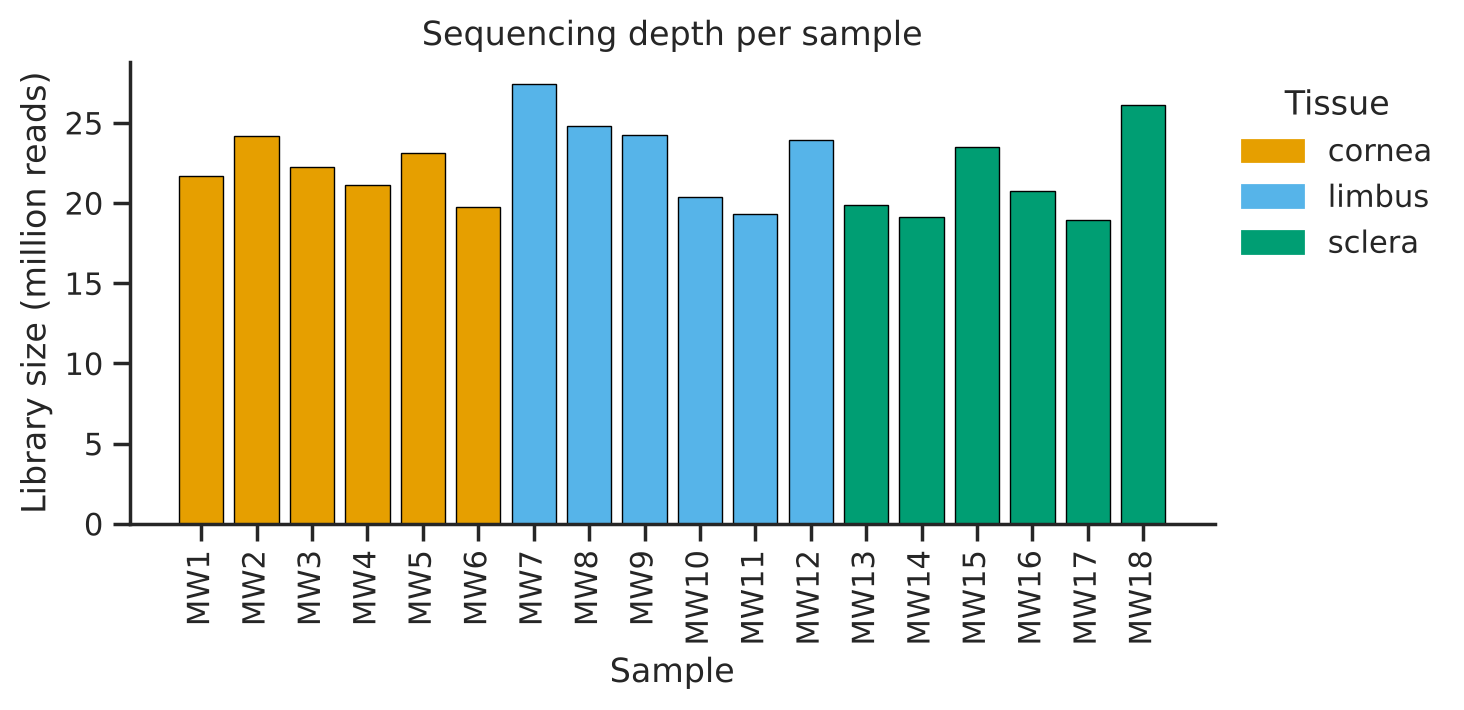

In [9]:
# Step 2 – build a legend by hand: one coloured patch per tissue, placed outside the plot
from matplotlib.patches import Patch
handles = [Patch(color=c, label=t) for t, c in TISSUE_COLORS.items()]
ax.legend(handles=handles, title="Tissue", frameon=False, bbox_to_anchor=(1, 1))
fig

### ✏️ Exercise 1 – A horizontal bar chart

Long sample names are easier to read on the y-axis. Re-draw the library-size plot as a **horizontal** bar chart
(`ax.barh`) with bars coloured by **condition** (`CONDITION_COLORS`), and add a dashed vertical line at the median
library size (`ax.axvline`). Run the three steps one after the other and watch the figure change.

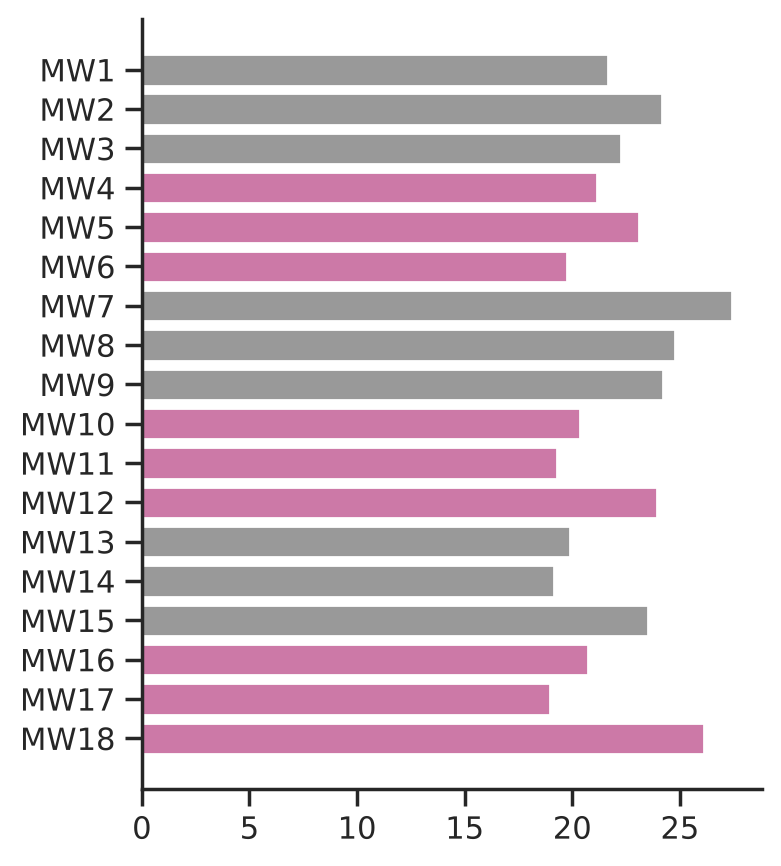

In [10]:
# Step 1 – horizontal bars coloured by condition
fig, ax = plt.subplots(figsize=(4, 5))
ax.barh(meta["sample"], lib_size[meta["sample"]], color=meta["condition"].map(CONDITION_COLORS))
ax.invert_yaxis()            # first sample at the top
plt.show()

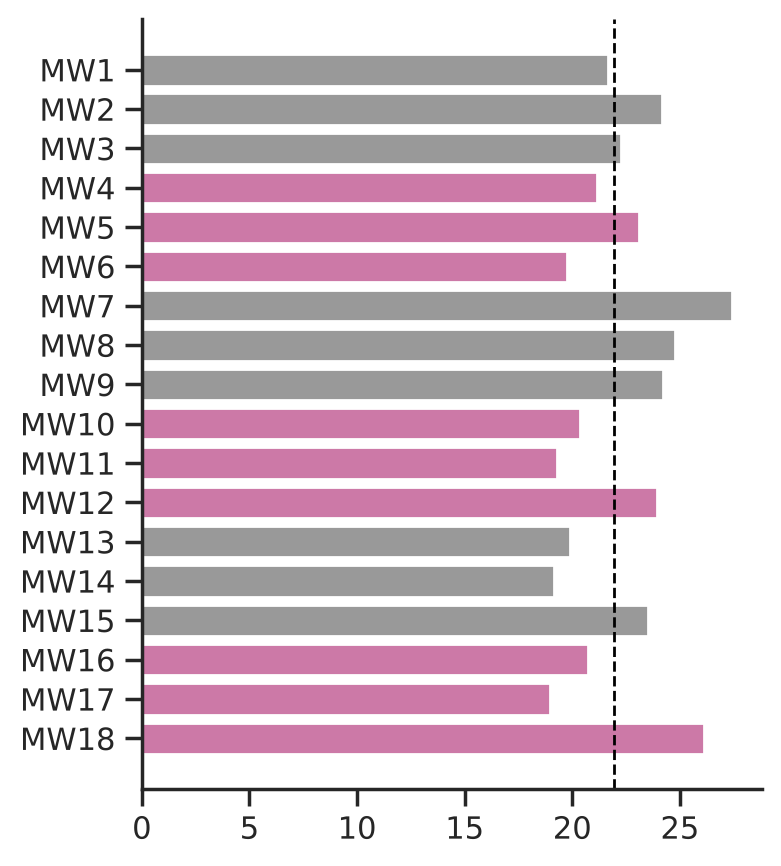

In [11]:
# Step 2 – dashed line at the median library size
ax.axvline(lib_size.median(), color="black", linestyle="--", linewidth=1)
fig

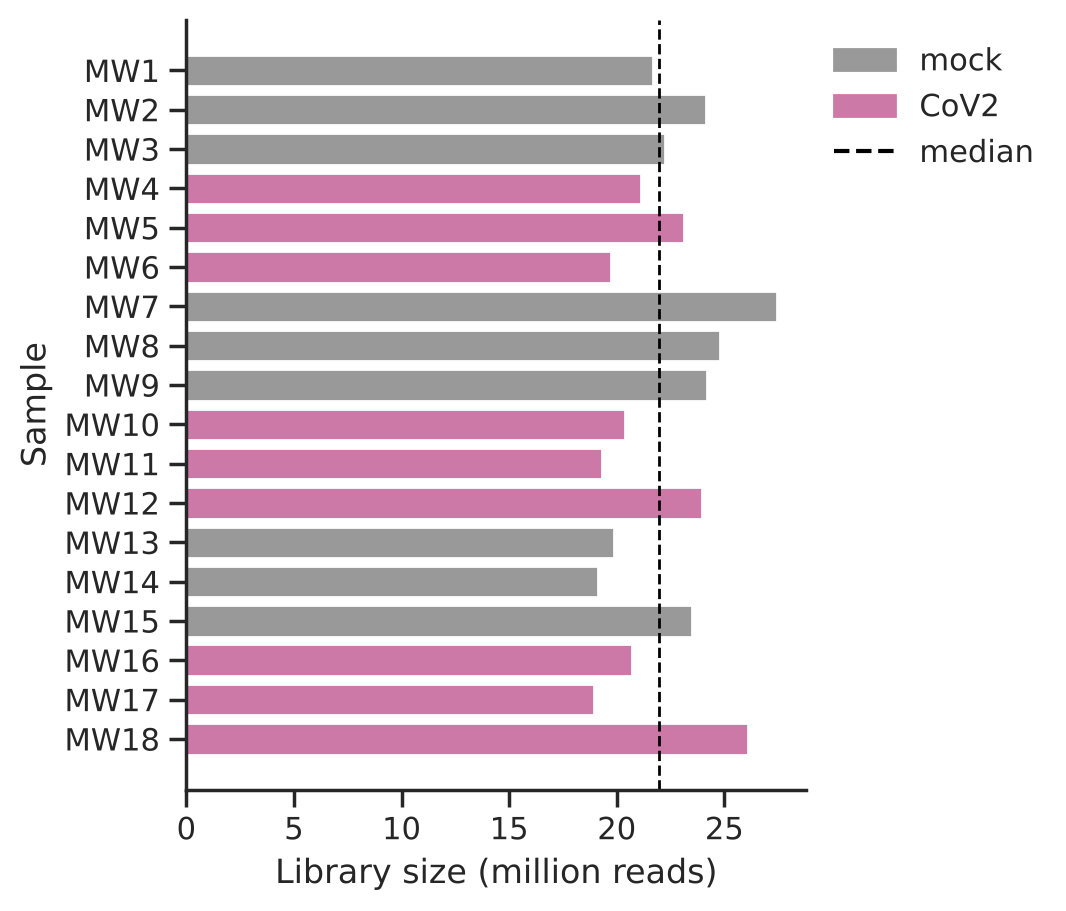

In [12]:
# Step 3 – axis labels and legend
ax.set(xlabel="Library size (million reads)", ylabel="Sample")
handles = [Patch(color=c, label=k) for k, c in CONDITION_COLORS.items()]
ax.legend(handles=handles + [plt.Line2D([], [], color="black", ls="--", label="median")],
          frameon=False, bbox_to_anchor=(1, 1), loc="upper left")
fig

---
## Module 2 – Seaborn, tidy data & distributions

[Seaborn](https://seaborn.pydata.org/tutorial/function_overview.html) is a high-level *statistical* plotting library
built on Matplotlib. You hand it a **DataFrame** and tell it which **columns** map to x, y, colour (`hue`)… and it does
the grouping, colouring, legends and statistics for you.

Seaborn works best with **tidy ("long") data**: *one row per observation, one column per variable*.
Our expression matrix is "wide" (genes × samples), so we **melt** it.

In [13]:
# Wide -> long, then attach the sample metadata
expr_long = (expr.reset_index()
                 .melt(id_vars="gene", var_name="sample", value_name="log2cpm")
                 .merge(meta, on="sample"))
expr_long.head()

,gene,sample,log2cpm,tissue,condition
0,A1BG,MW1,2.3783,cornea,mock
1,A1BG-AS1,MW1,3.8554,cornea,mock
2,A2M,MW1,3.6743,cornea,mock
3,A4GALT,MW1,4.5039,cornea,mock
4,AAAS,MW1,5.3899,cornea,mock


#### Two families of Seaborn functions

* **Axes-level** (`sns.boxplot`, `sns.violinplot`, `sns.scatterplot`, `sns.heatmap`…) draw on **one Axes** → you can pass
  `ax=` and place them inside your own Matplotlib layout.
* **Figure-level** (`sns.displot`, `sns.catplot`, `sns.relplot`, `sns.clustermap`) create **their own figure**, and make
  it easy to split the data into small multiples with `col=` / `row=`.

Let's look at the distribution of expression values in every sample (a classic QC plot).

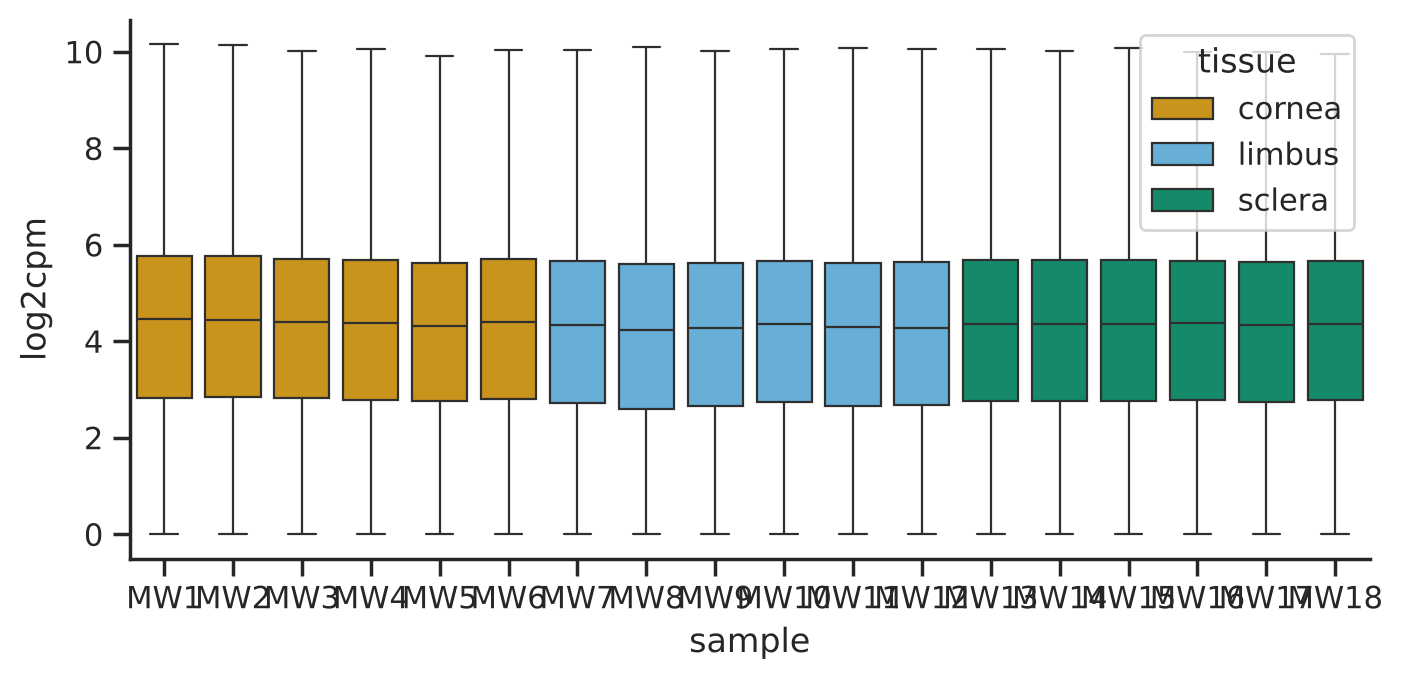

In [14]:
# Step 1 – one Seaborn call draws all 18 boxes on our Axes (axes-level -> ax=)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.boxplot(data=expr_long, x="sample", y="log2cpm", hue="tissue",
            palette=TISSUE_COLORS, showfliers=False, linewidth=0.8, ax=ax)
plt.show()

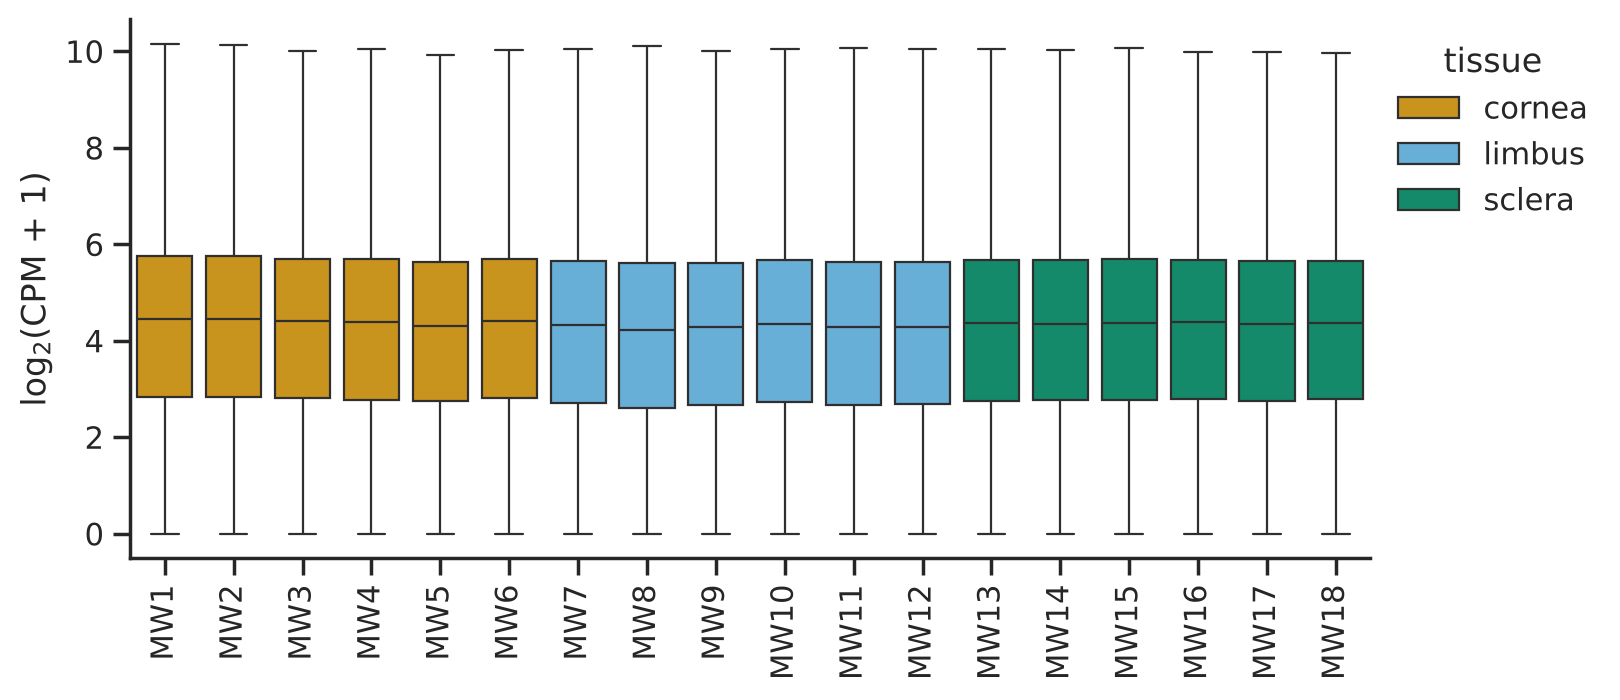

In [15]:
# Step 2 – it is still a normal Matplotlib Axes: tidy up labels, ticks and legend
ax.set(xlabel="", ylabel="log$_2$(CPM + 1)")
ax.tick_params(axis="x", rotation=90)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), frameon=False)
fig

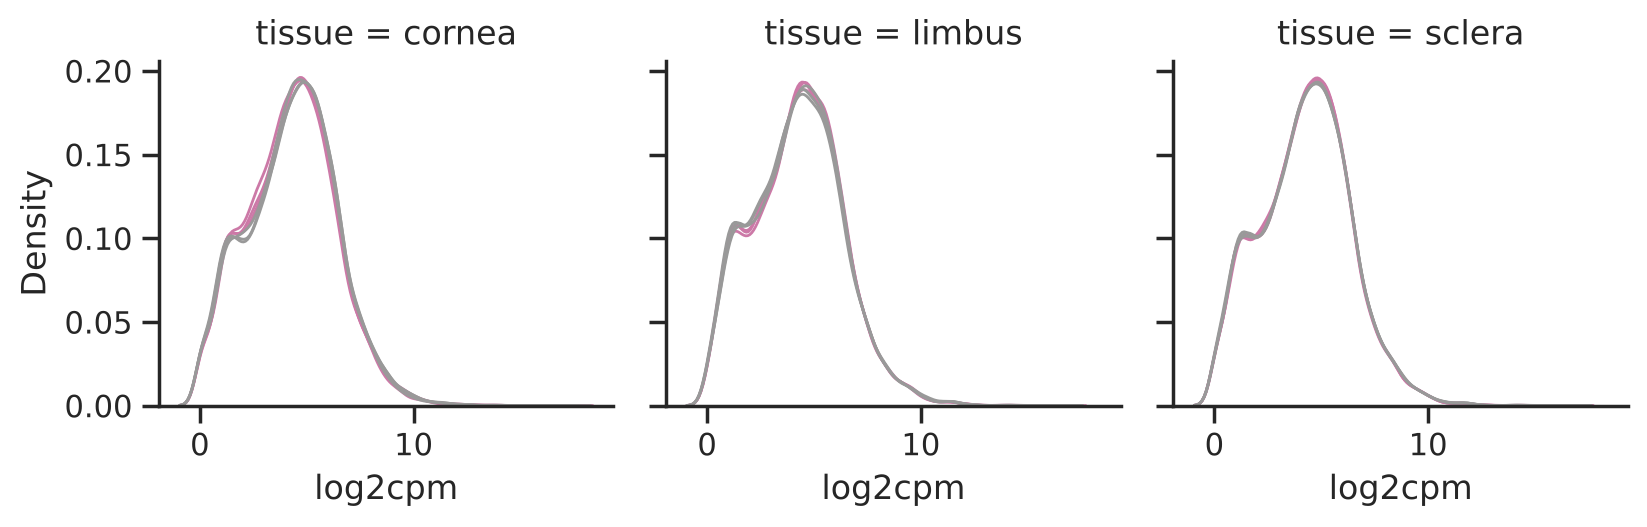

In [16]:
# (Optional) Step 1 – figure-level: one density curve per sample (hue="sample"), coloured by its condition,
# one panel per tissue (col="tissue")
sample_colors = dict(zip(meta["sample"], meta["condition"].map(CONDITION_COLORS)))

g = sns.displot(data=expr_long, x="log2cpm", hue="sample", col="tissue", kind="kde",
                palette=sample_colors, col_order=TISSUE_ORDER, common_norm=False,
                linewidth=1, height=2.8, aspect=1, legend=False)
plt.show()

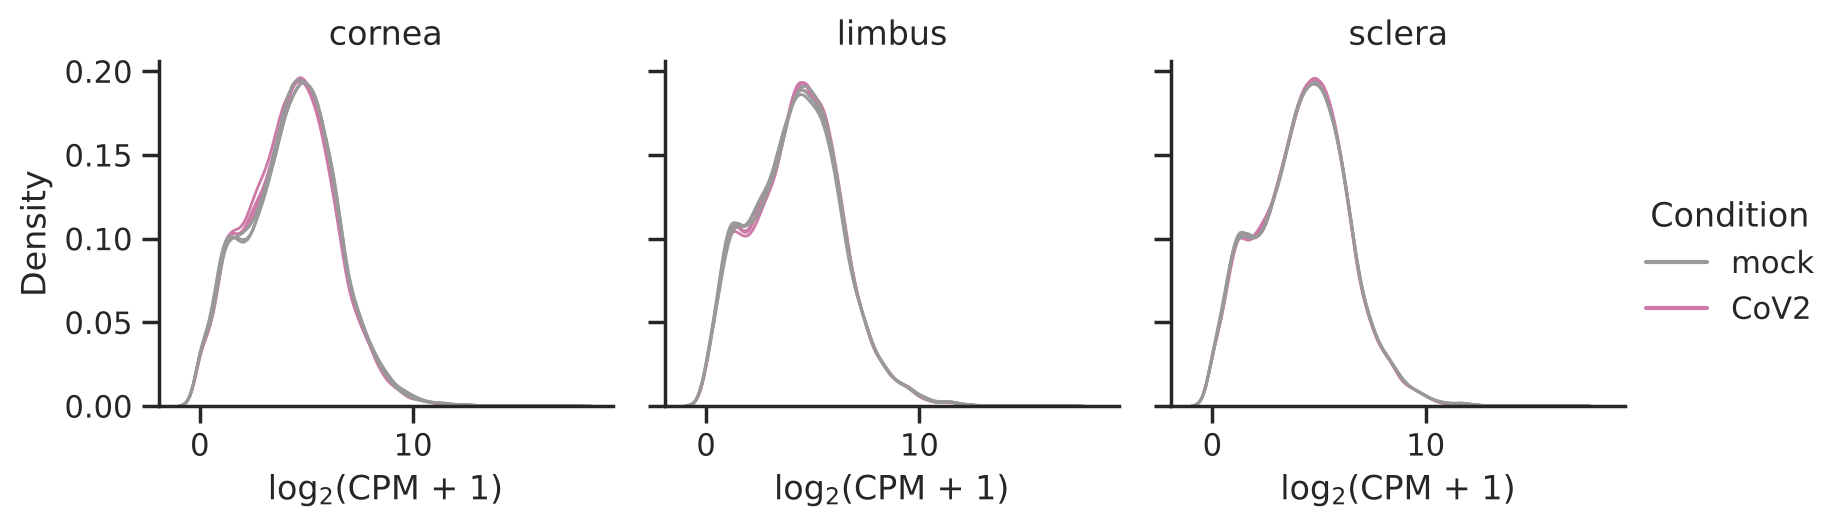

In [17]:
# (Optional) Step 2 – figure-level functions return a grid object `g`; customise it, then show g.figure
g.set_axis_labels("log$_2$(CPM + 1)", "Density")
g.set_titles("{col_name}")
g.add_legend(legend_data={k: plt.Line2D([], [], color=c) for k, c in CONDITION_COLORS.items()},
             title="Condition")
g.figure

> 💡 Drawing one curve *per sample* (instead of one per group) lets you spot an outlier sample before trusting group
> summaries. Here all samples have very similar distributions – good news for the normalisation.

#### Showing a single gene: **show the points!**

With only *n = 3* per group, a bar of the mean hides everything. Overlaying the individual data points on a box (or
using a strip plot alone) shows the reader your real sample size and spread.

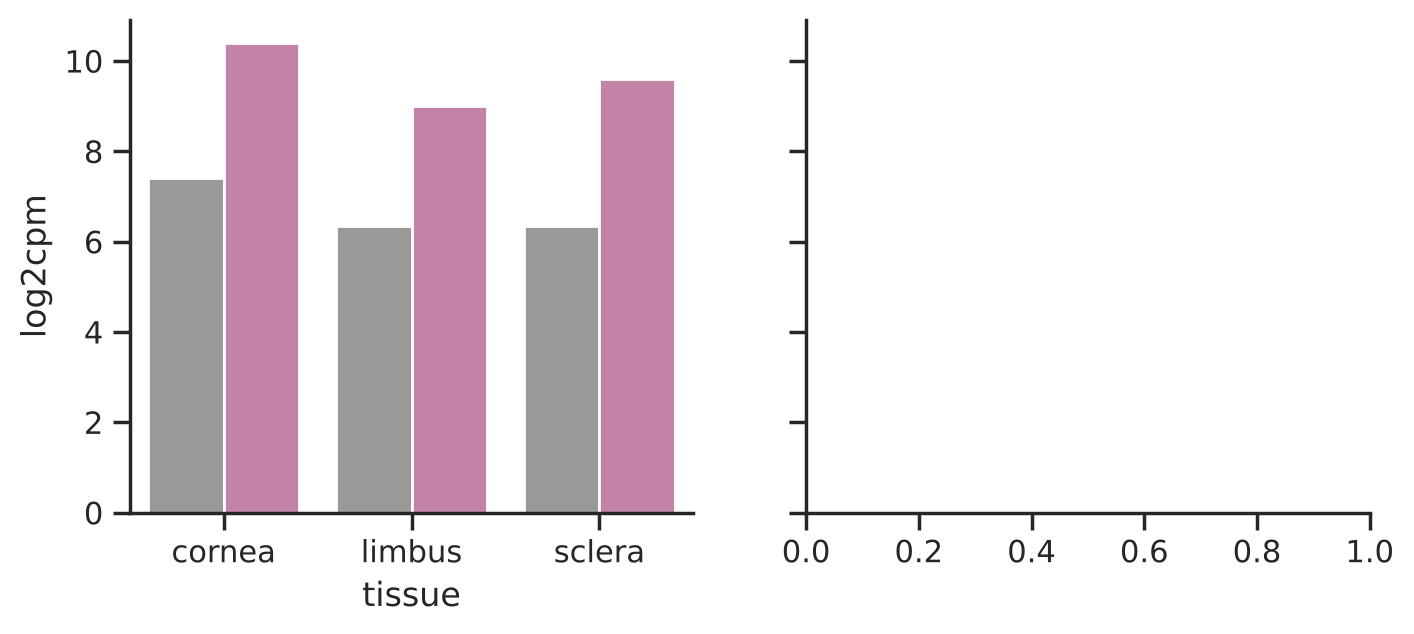

In [18]:
# Step 1 – two Axes side by side; on the left, a bar chart of the means
gene = "SOD2"
df_gene = expr_long[expr_long["gene"] == gene]

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
sns.barplot(data=df_gene, x="tissue", y="log2cpm", hue="condition", palette=CONDITION_COLORS,
            order=TISSUE_ORDER, errorbar=None, ax=axes[0], legend=False)
plt.show()

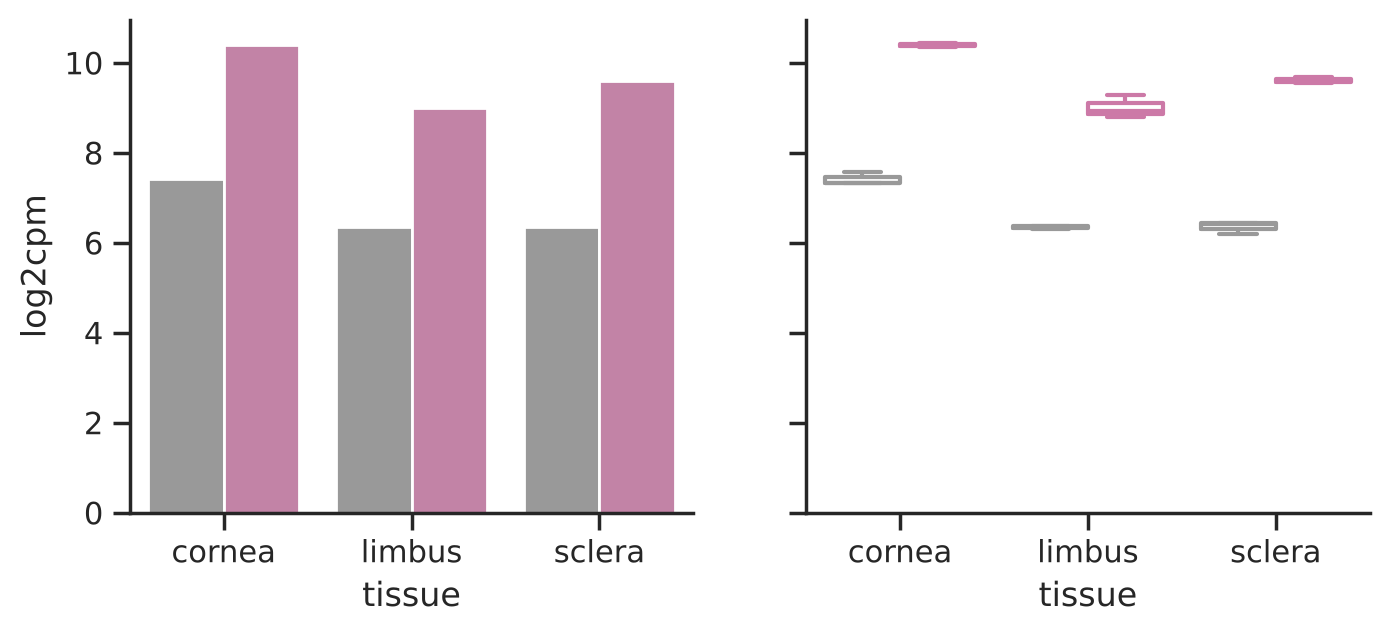

In [19]:
# Step 2 – on the right, a box plot of the same data
sns.boxplot(data=df_gene, x="tissue", y="log2cpm", hue="condition", palette=CONDITION_COLORS,
            order=TISSUE_ORDER, fill=False, showfliers=False, ax=axes[1], legend=False)
fig

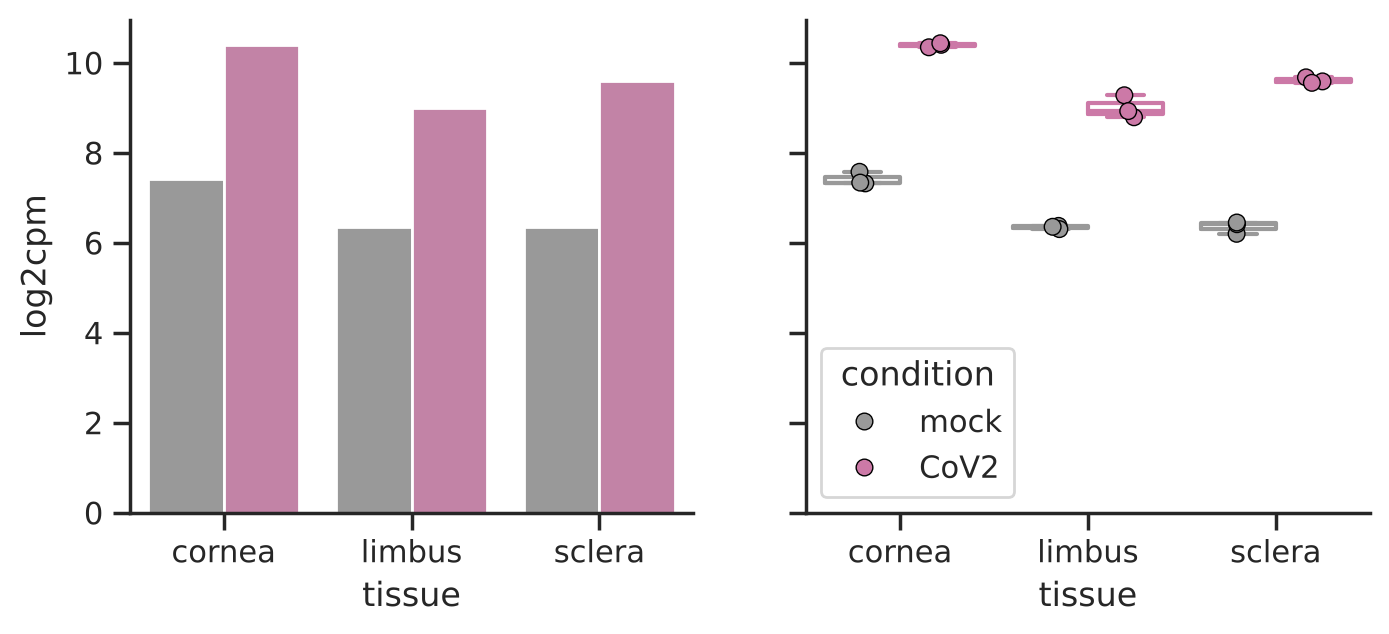

In [20]:
# Step 3 – overlay the individual samples (now the real n = 3 is visible)
sns.stripplot(data=df_gene, x="tissue", y="log2cpm", hue="condition", palette=CONDITION_COLORS,
              order=TISSUE_ORDER, dodge=True, size=6, edgecolor="black", linewidth=0.5, ax=axes[1])
fig

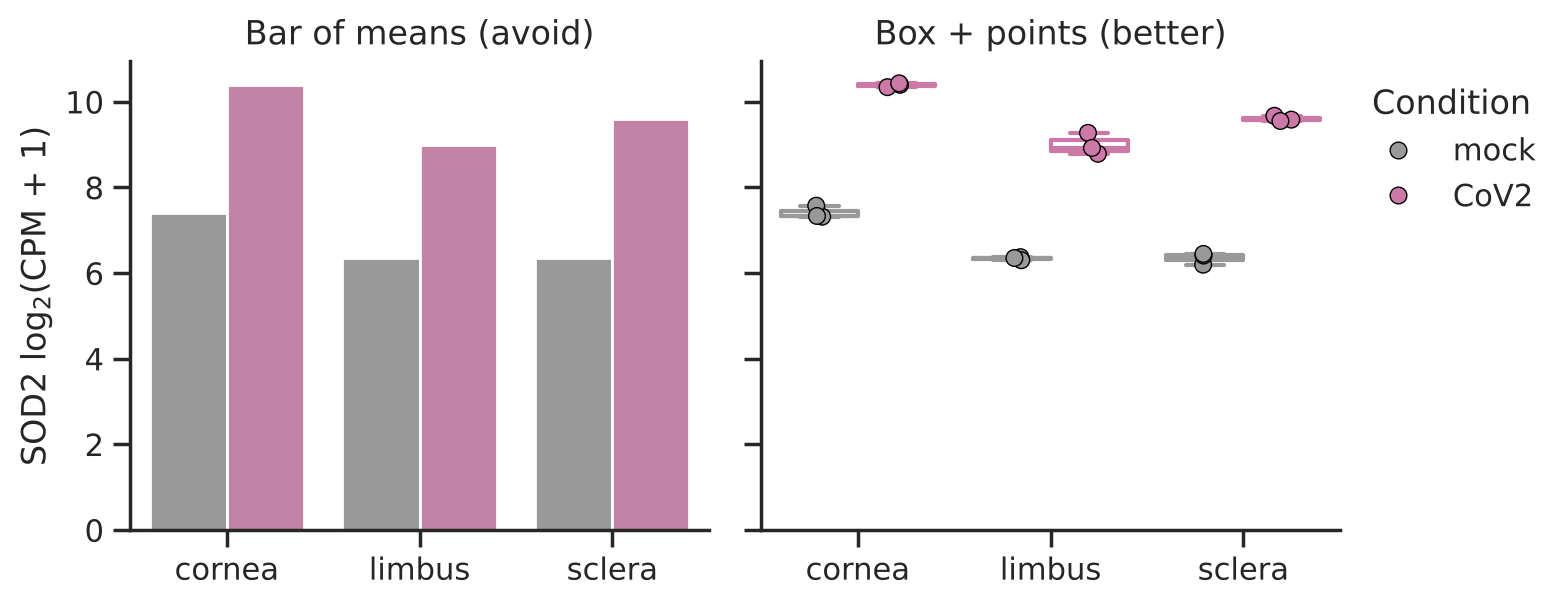

In [21]:
# Step 4 – titles, labels and legend
axes[0].set_title("Bar of means (avoid)")
axes[1].set_title("Box + points (better)")
for ax in axes:
    ax.set(xlabel="", ylabel=f"{gene} log$_2$(CPM + 1)")
sns.move_legend(axes[1], "upper left", bbox_to_anchor=(1, 1), frameon=False, title="Condition")
fig.tight_layout()
fig

### ✏️ Exercise 2 – Small multiples with `catplot`

Use the **figure-level** `sns.catplot` to show the expression of four inflammation genes
(`IL6`, `ICAM1`, `TNFAIP3`, `C3`) – **one panel per gene** – with tissue on the x-axis and points coloured by condition.

*Hints:* filter `expr_long` with `.isin()`, use `kind="strip"`, `col="gene"`, `col_wrap=2`, and `sharey=False`
(why do we need that?).

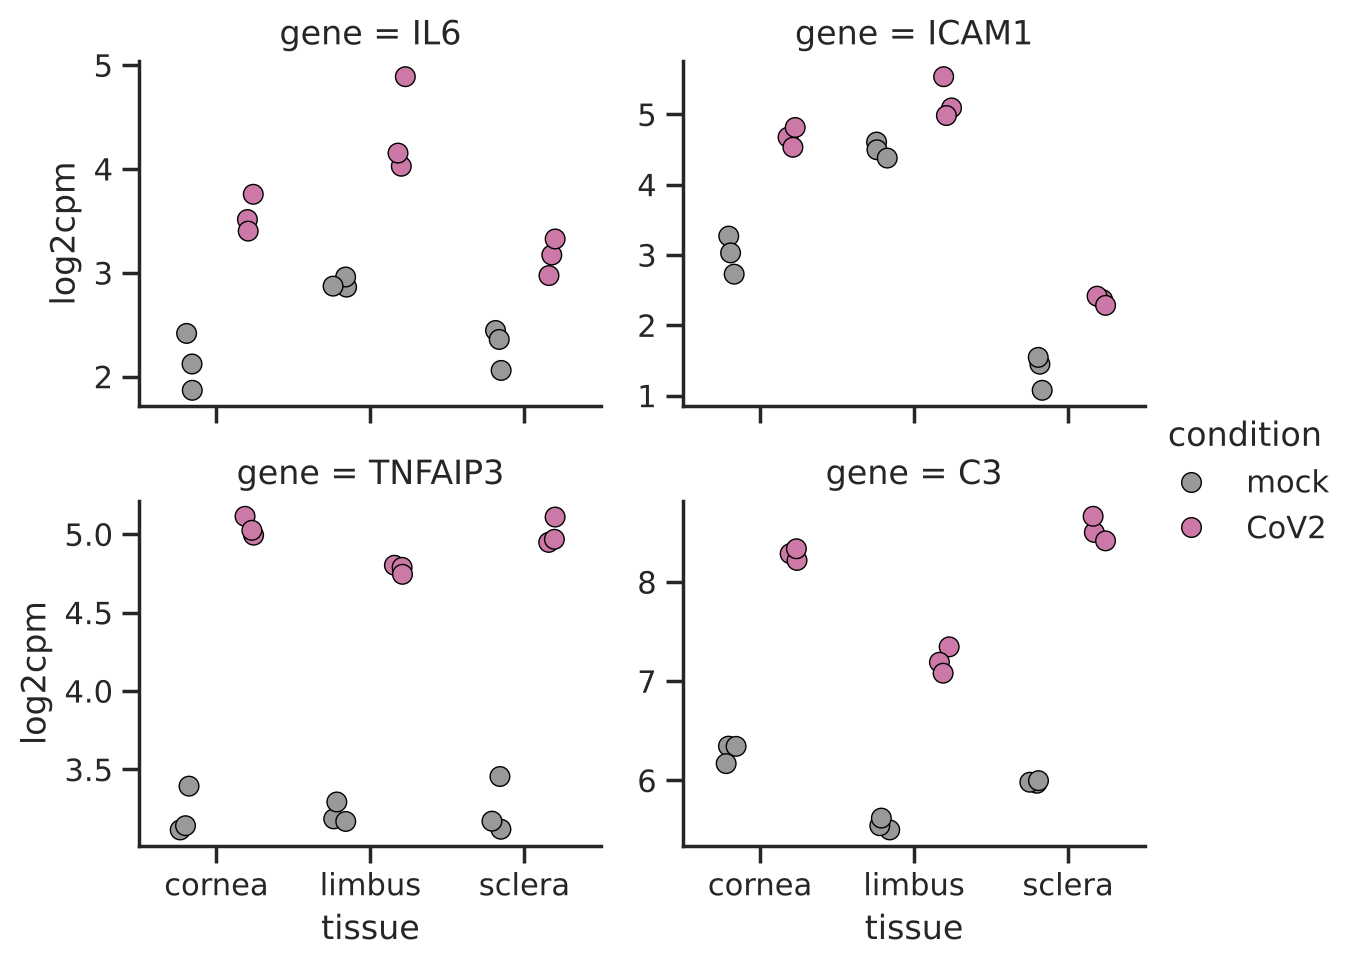

In [22]:
# Step 1 – draw the small multiples
genes = ["IL6", "ICAM1", "TNFAIP3", "C3"]
df = expr_long[expr_long["gene"].isin(genes)]

g = sns.catplot(data=df, x="tissue", y="log2cpm", hue="condition", col="gene", col_wrap=2,
                col_order=genes, kind="strip", dodge=True, palette=CONDITION_COLORS, order=TISSUE_ORDER,
                sharey=False, height=2.5, aspect=1.2, s=50, edgecolor="black", linewidth=0.5)
plt.show()
# sharey=False: genes have very different baseline expression, a shared axis would flatten the differences.

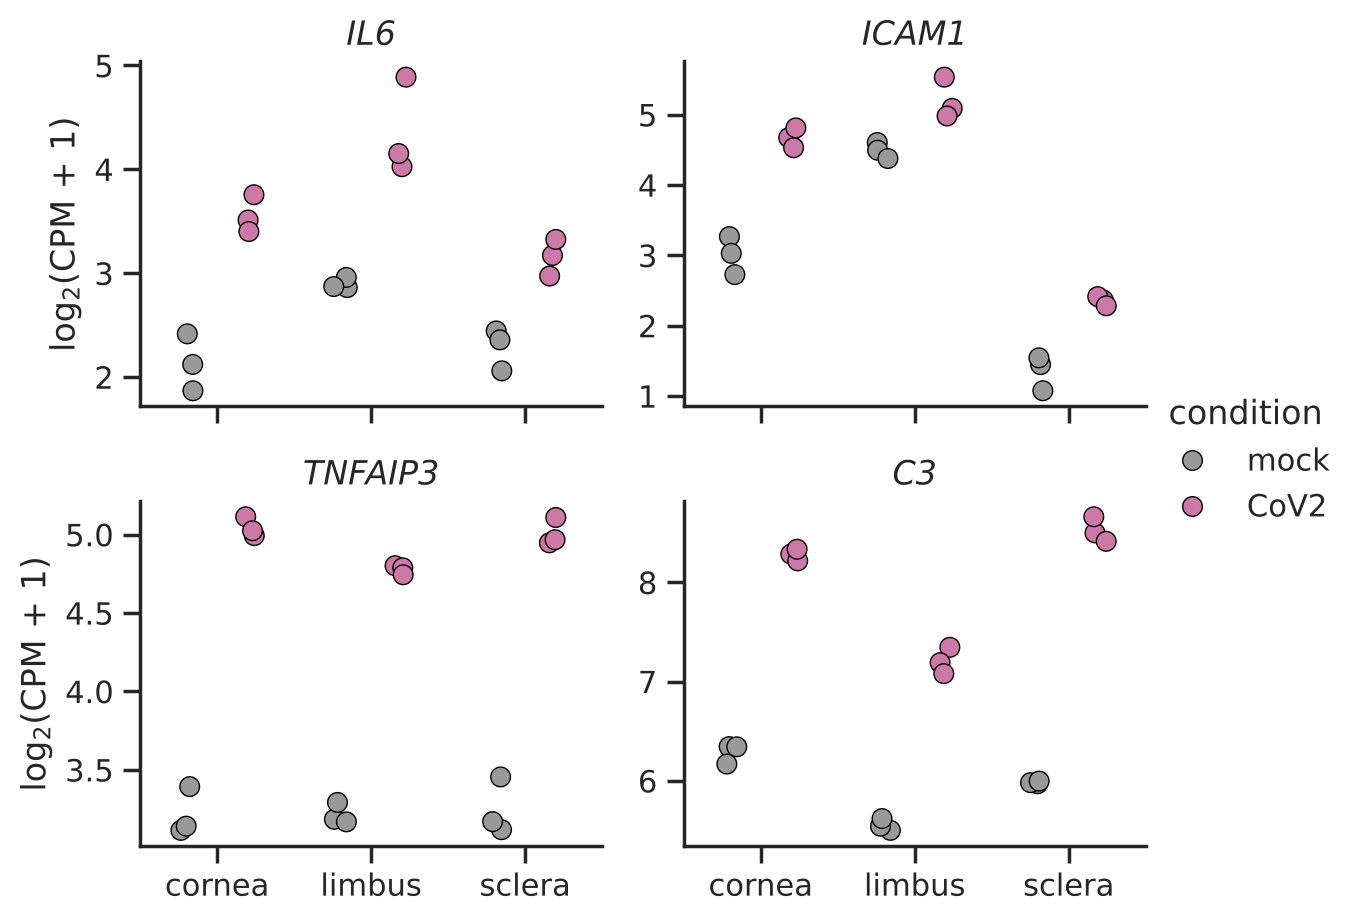

In [23]:
# Step 2 – panel titles and axis labels
g.set_titles("{col_name}", fontstyle="italic")   # gene symbols are conventionally italic
g.set_axis_labels("", "log$_2$(CPM + 1)")
g.figure

---
## Module 3 – Relationships: scatter, MA & volcano plots

Scatter plots show how two continuous variables relate. In genomics, two scatter plots summarise a differential
expression (DE) analysis:

* **Volcano plot** – effect size (log$_2$ fold change) vs. significance (−log$_{10}$ adjusted p-value)
* **MA plot** – average expression vs. log$_2$ fold change

We'll use the cornea CoV2-vs-mock results. First, label each gene by its DE status.

In [24]:
PADJ, LFC = 0.05, 1          # thresholds: adjusted p < 0.05 and |log2FC| > 1

de["neg_log10_padj"] = -np.log10(de["padj"])
de["status"] = "not significant"
de.loc[(de.padj < PADJ) & (de.log2FoldChange >  LFC), "status"] = "up in CoV2"
de.loc[(de.padj < PADJ) & (de.log2FoldChange < -LFC), "status"] = "down in CoV2"
DE_COLORS = {"up in CoV2": "#D55E00", "down in CoV2": "#0072B2", "not significant": "#BBBBBB"}

de["status"].value_counts()

status
not significant    13248
down in CoV2          66
up in CoV2            60
Name: count, dtype: int64

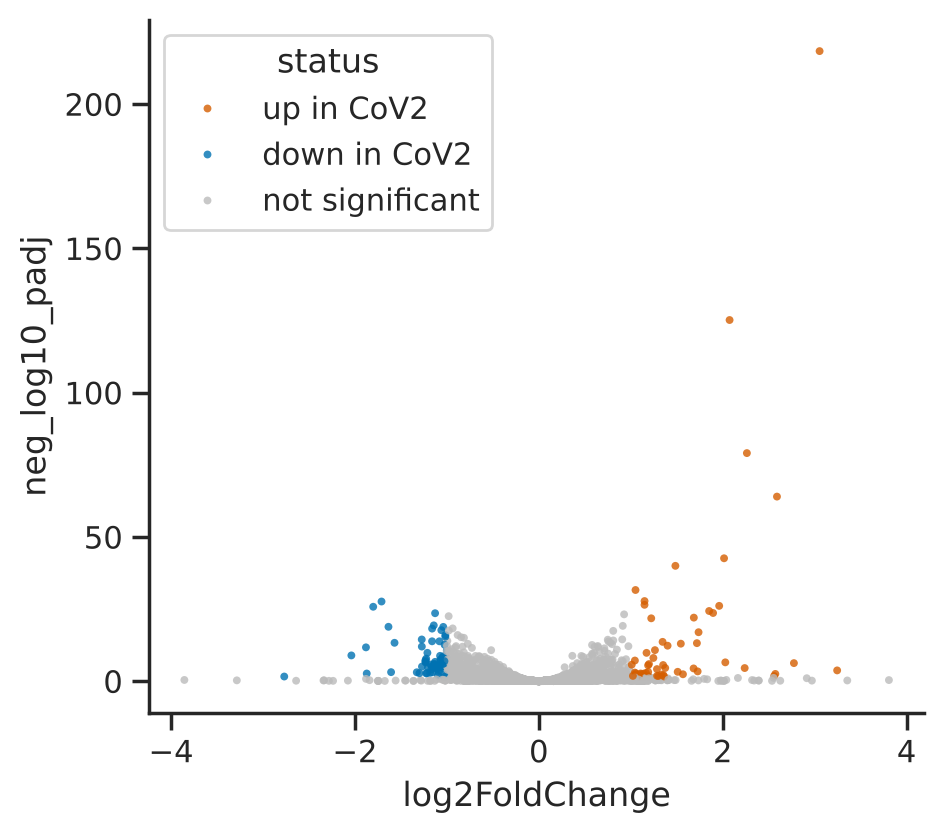

In [25]:
# Step 1 – the scatter plot itself, one point per gene, coloured by DE status
fig, ax = plt.subplots(figsize=(5, 4.5))
sns.scatterplot(data=de, x="log2FoldChange", y="neg_log10_padj", hue="status", palette=DE_COLORS,
                hue_order=list(DE_COLORS), s=8, linewidth=0, alpha=0.8, rasterized=True, ax=ax)
plt.show()

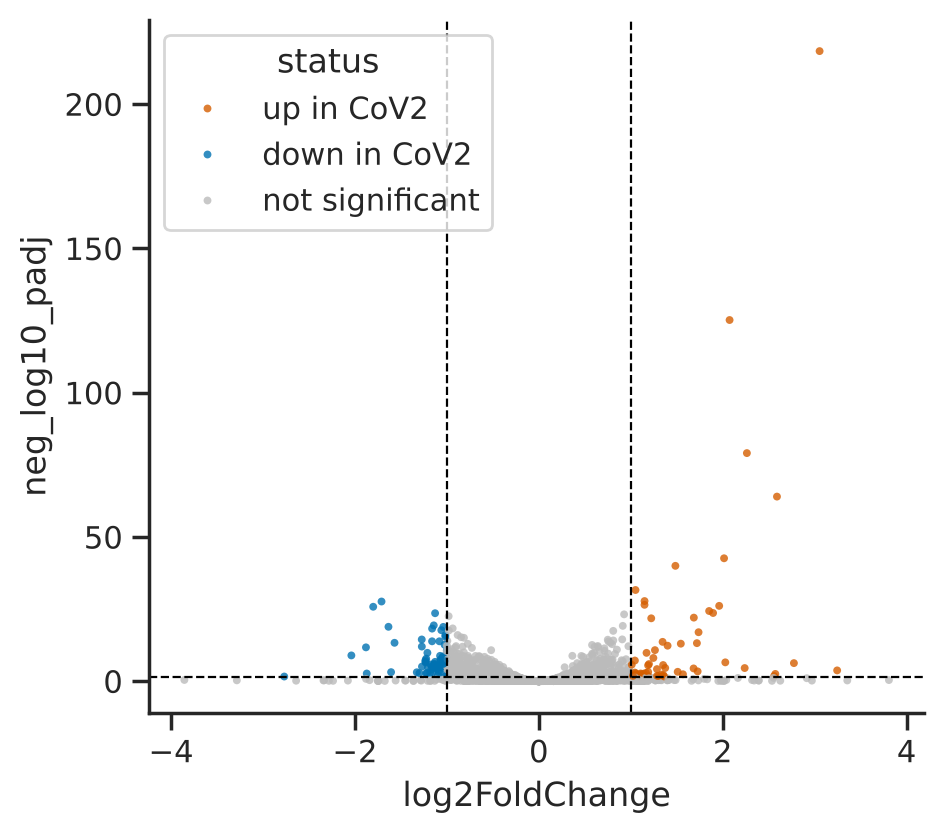

In [26]:
# Step 2 – dashed threshold lines
ax.axhline(-np.log10(PADJ), color="black", ls="--", lw=0.8)
for x in (-LFC, LFC):
    ax.axvline(x, color="black", ls="--", lw=0.8)
fig

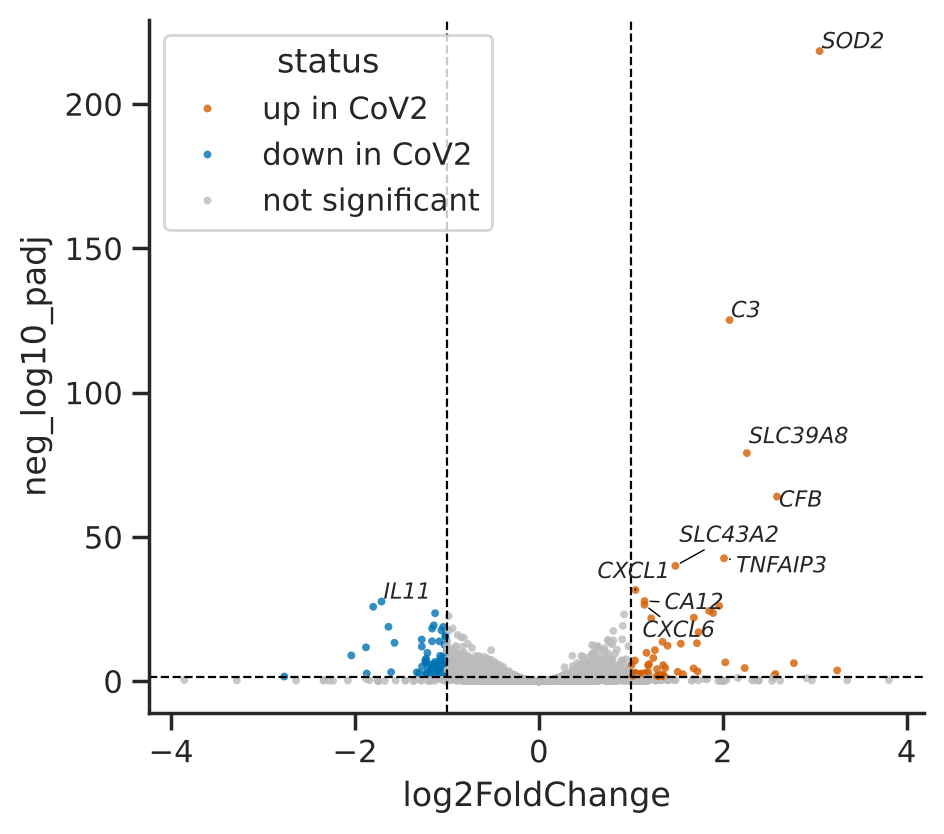

In [27]:
# Step 3 – label the top genes (most significant among the strongly changed ones).
# adjustText nudges the labels so they don't overlap each other or the points.
from adjustText import adjust_text
top = de[de.status != "not significant"].nsmallest(10, "padj")
texts = [ax.text(r.log2FoldChange, r.neg_log10_padj, g, fontsize=8, fontstyle="italic")
         for g, r in top.iterrows()]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="black", lw=0.5))
fig

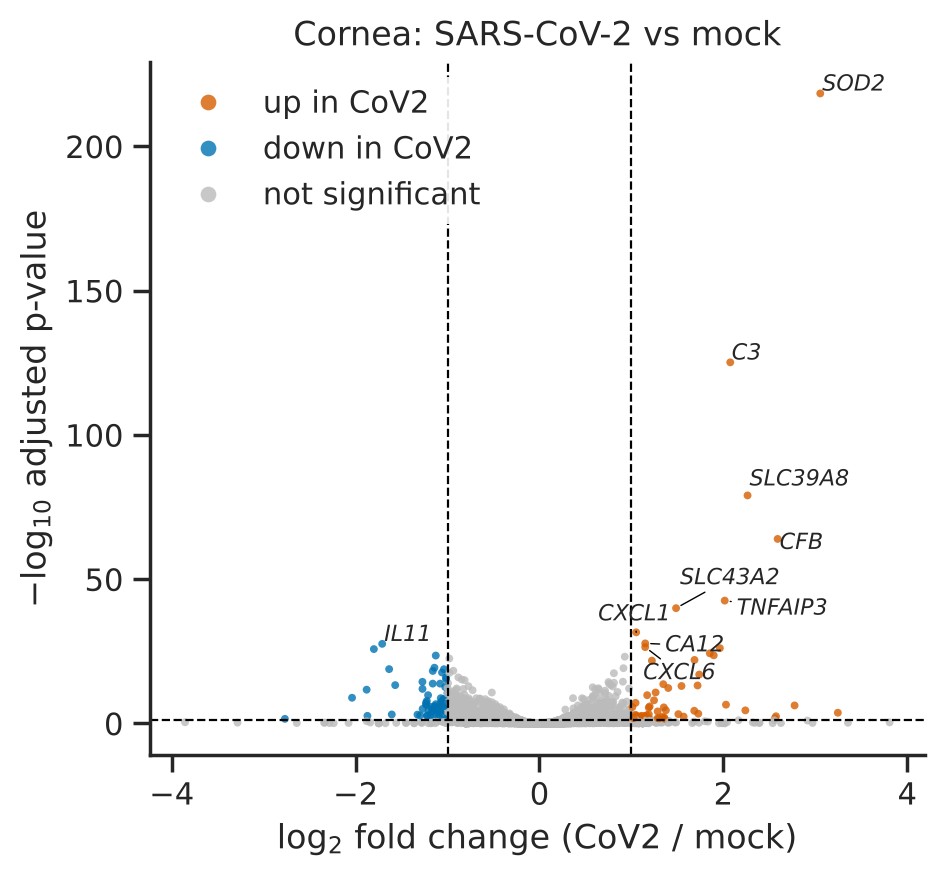

In [28]:
# Step 4 – axis labels with units, title and a cleaner legend
ax.set(xlabel="log$_2$ fold change (CoV2 / mock)", ylabel="−log$_{10}$ adjusted p-value",
       title="Cornea: SARS-CoV-2 vs mock")
ax.legend(markerscale=2, title=None, frameon=True, framealpha=0.9, edgecolor="none", loc="upper left")
fig

> 💡 **`rasterized=True`** – a volcano plot has >10,000 points. Saved as a vector PDF, each point is a separate object,
> which makes files huge and Inkscape slow. Rasterising *only the points* keeps axes and text as editable vectors.

### ✏️ Exercise 3 – MA plot

Make an **MA plot** of the same results: `log10(baseMean)` on the x-axis, `log2FoldChange` on the y-axis, coloured by
`status`. Add a horizontal line at y = 0 and make sure your axis labels have units.

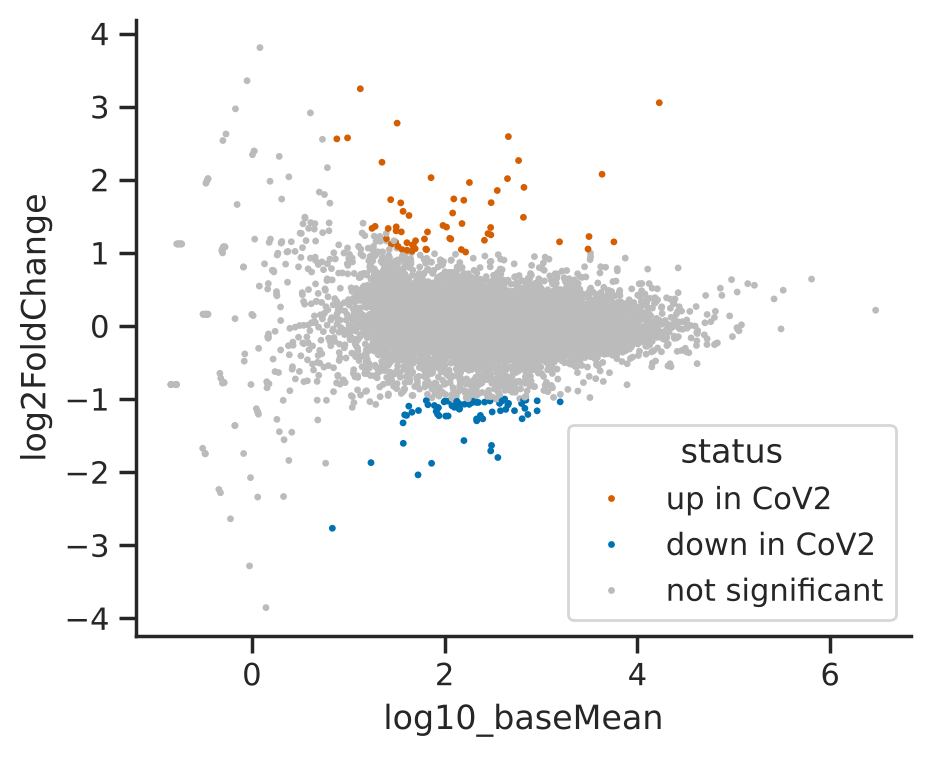

In [29]:
# Step 1 – scatter plot
de["log10_baseMean"] = np.log10(de["baseMean"])

fig, ax = plt.subplots(figsize=(5, 4))
sns.scatterplot(data=de, x="log10_baseMean", y="log2FoldChange", hue="status", palette=DE_COLORS,
                hue_order=list(DE_COLORS), s=6, linewidth=0, rasterized=True, ax=ax)
plt.show()

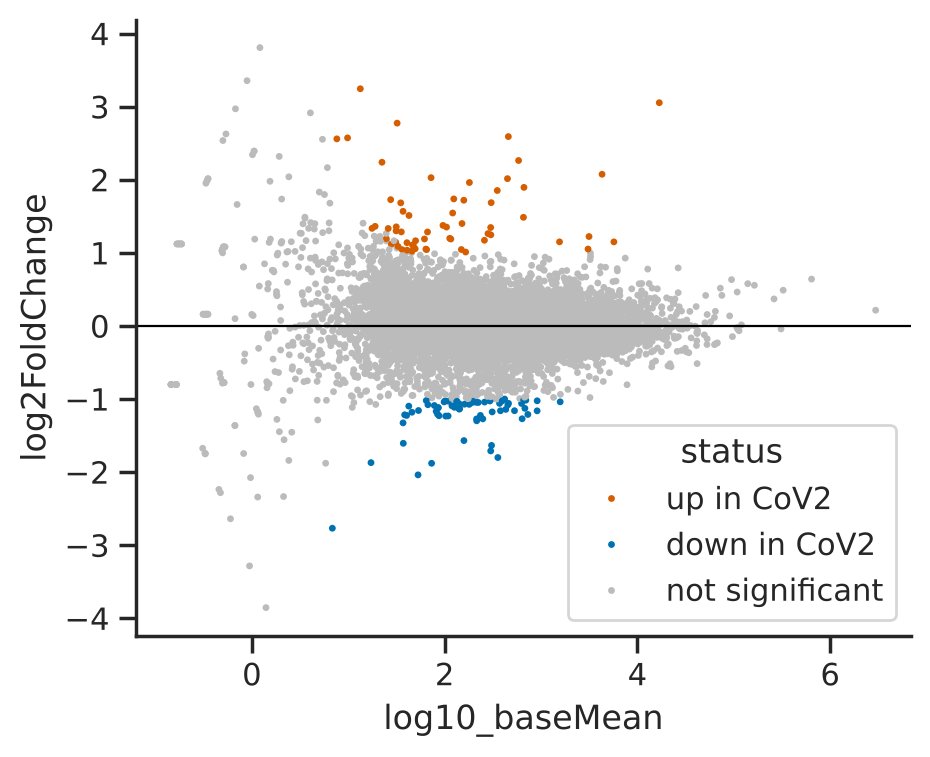

In [30]:
# Step 2 – reference line at "no change"
ax.axhline(0, color="black", lw=0.8)
fig

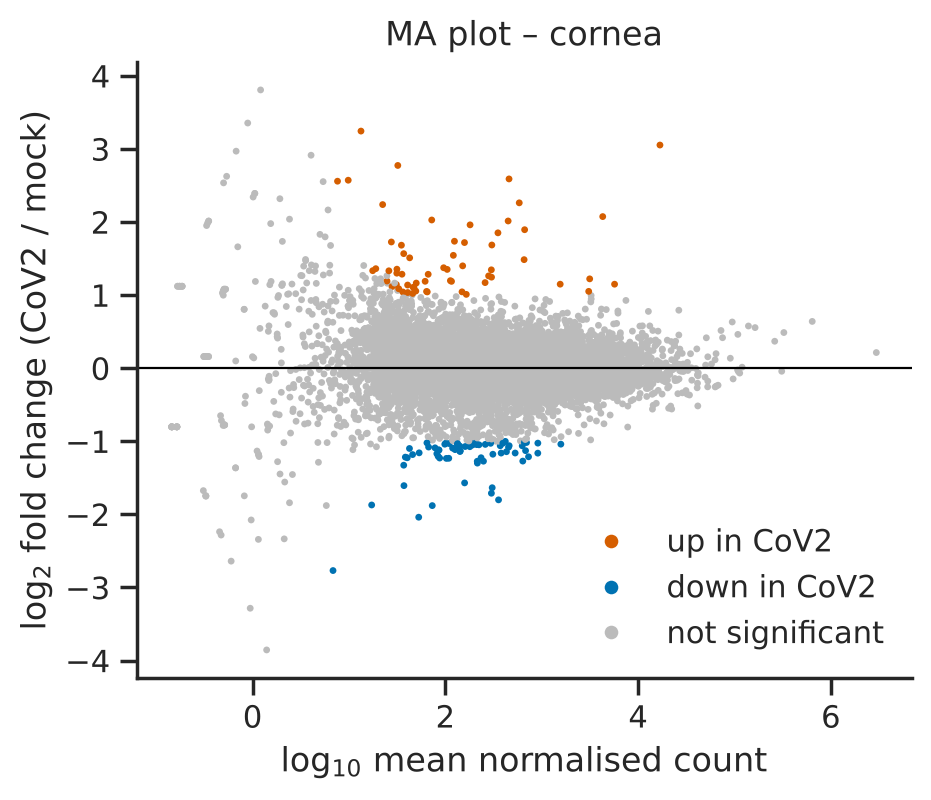

In [31]:
# Step 3 – labels and legend
ax.set(xlabel="log$_{10}$ mean normalised count", ylabel="log$_2$ fold change (CoV2 / mock)",
       title="MA plot – cornea")
ax.legend(frameon=False, markerscale=2)
fig

---
## Module 4 – Heatmaps & clustered heatmaps

Heatmaps show a matrix of values as colours. Two common uses:

1. **Sample–sample correlation** – do replicates look alike? do tissues separate?
2. **Gene × sample expression** – which genes drive the differences?

**Choosing a colour map** matters:

* *Sequential* (`viridis`, `rocket`, `mako`) for values going from low to high (e.g. correlation 0.9 → 1).
* *Diverging* (`vlag`, `RdBu_r`, `coolwarm`) for values centred on a meaningful midpoint (e.g. z-scores around 0).
* Avoid `jet` / rainbow: not perceptually uniform and not colour-blind safe.

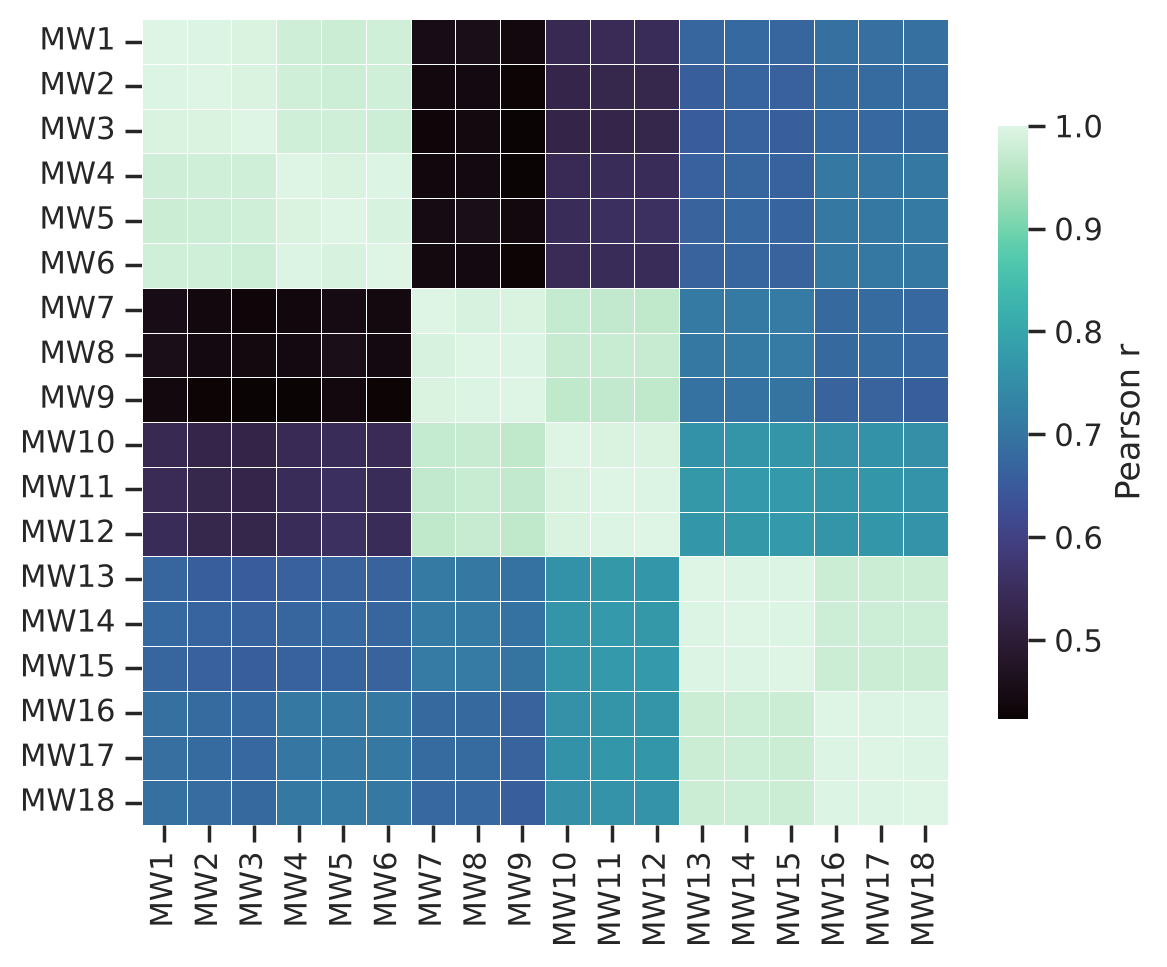

In [32]:
# (Optional) Step 1 – correlation between samples, using the 1,000 most variable genes
top_var = expr.var(axis=1).nlargest(1000).index
corr = expr.loc[top_var].corr(method="pearson")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr, cmap="mako", square=True, linewidths=0.3,
            cbar_kws={"label": "Pearson r", "shrink": 0.7}, ax=ax)
plt.show()

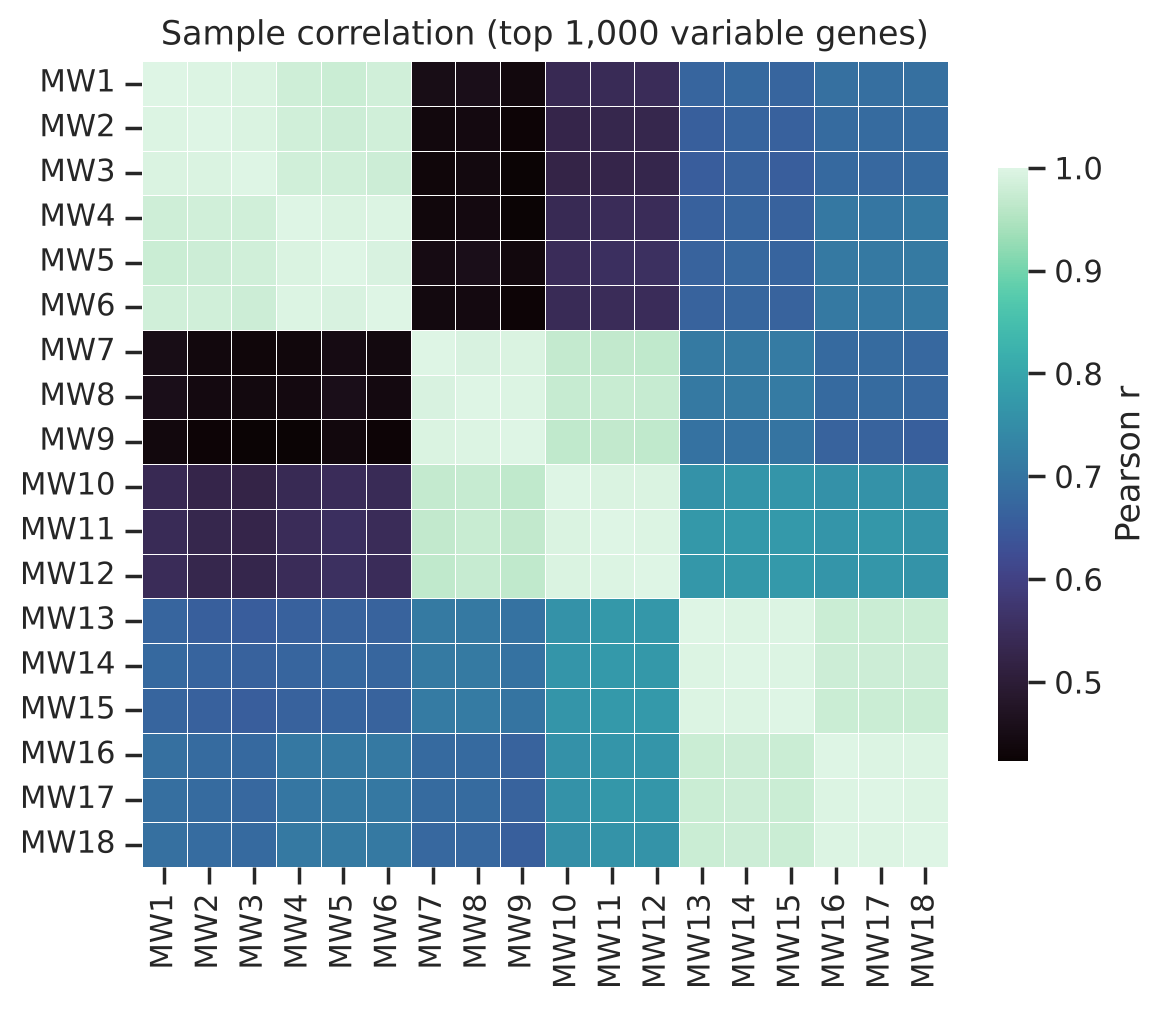

In [33]:
# (Optional) Step 2 – remove the redundant axis labels and add a title
ax.set(xlabel="", ylabel="", title="Sample correlation (top 1,000 variable genes)")
fig

#### Clustered heatmap with annotation bars

`sns.clustermap` (figure-level) reorders rows and columns by hierarchical clustering and can add **colour bars** that
show each sample's group. We **z-score each gene** (`z_score=0`) so that we compare *patterns* rather than absolute levels.

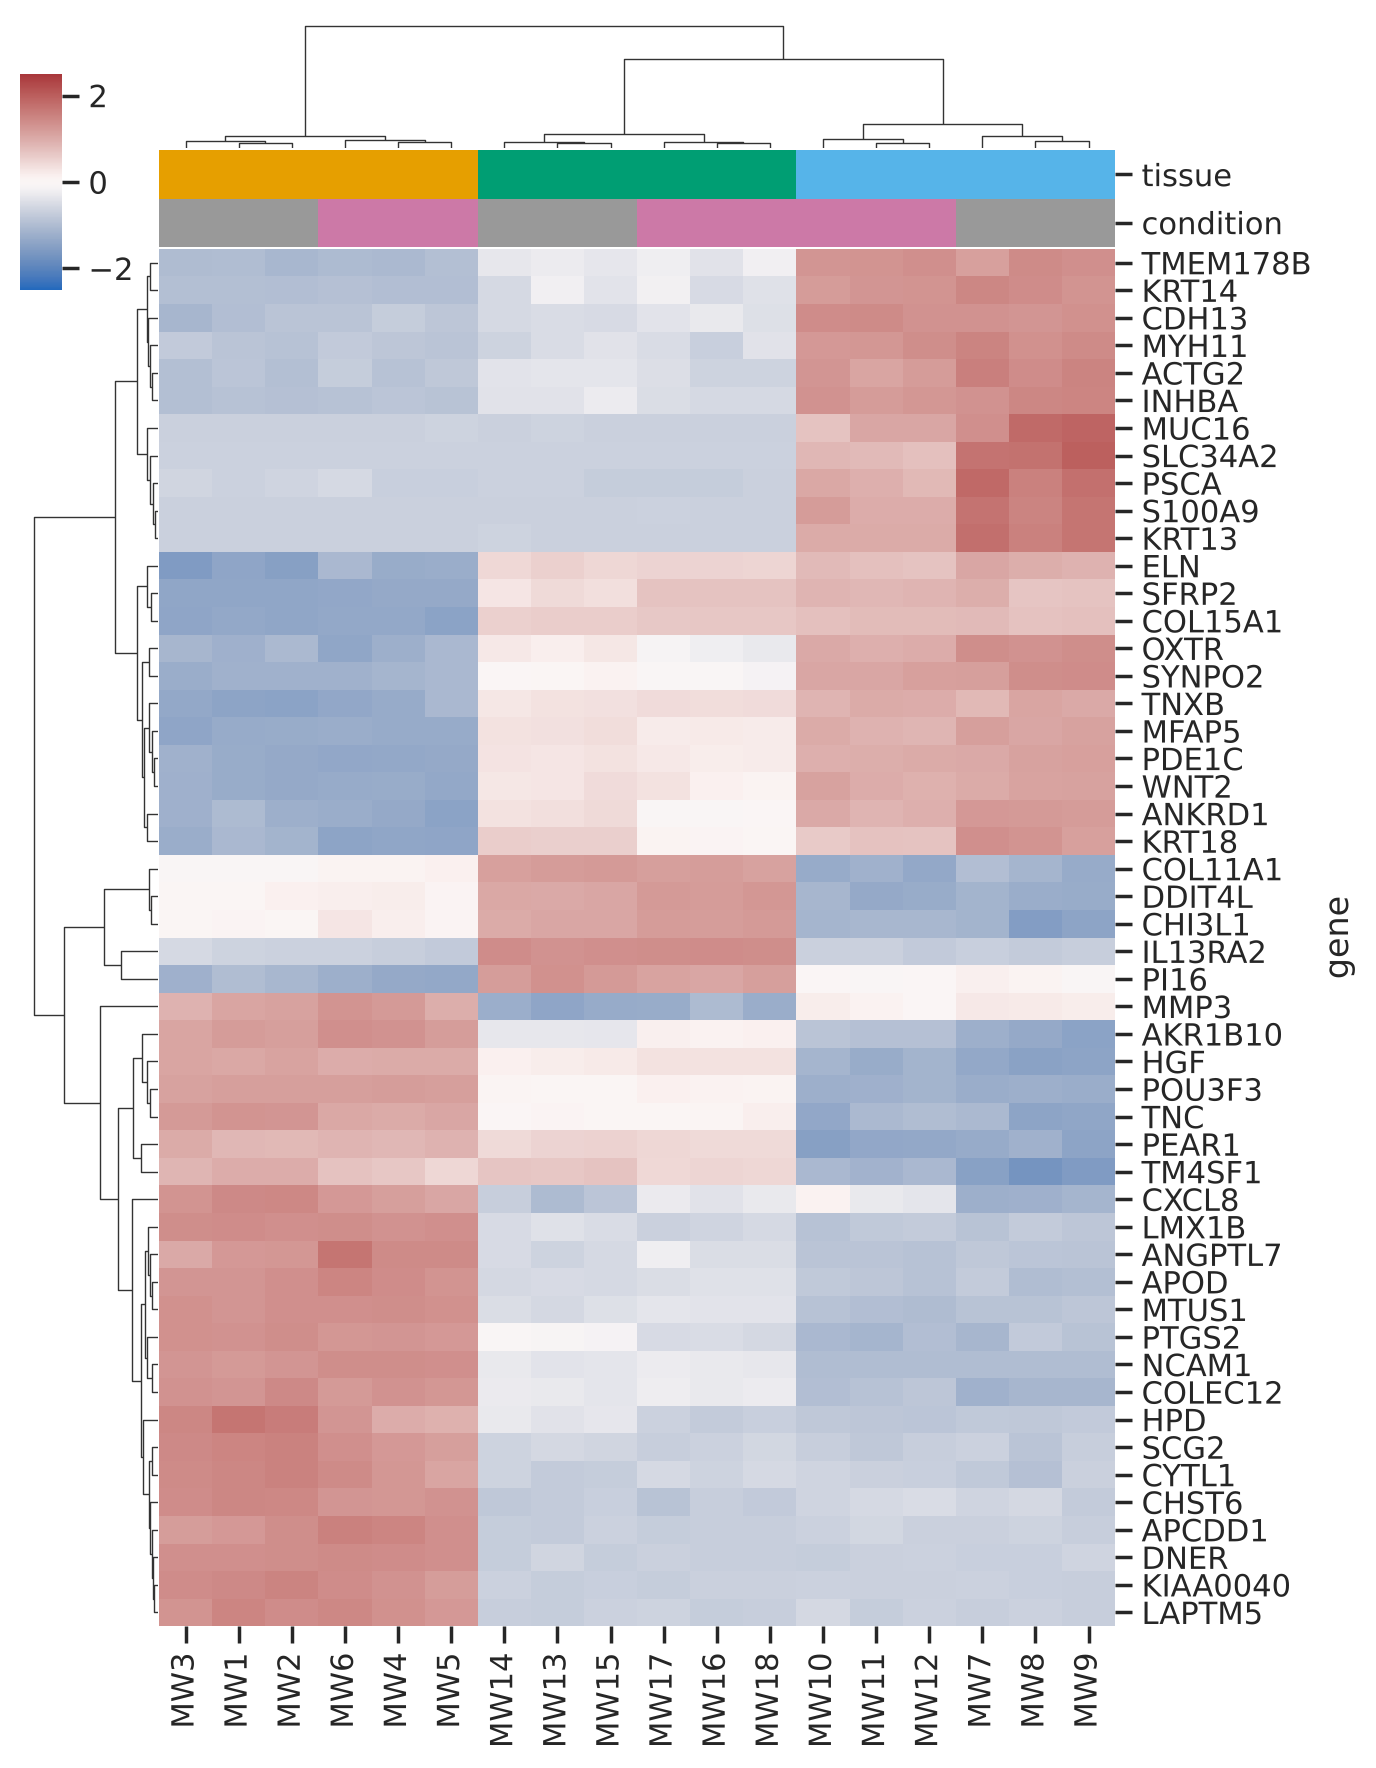

In [34]:
# Step 1 – clustered heatmap of the 50 most variable genes, with tissue/condition colour bars
top50 = expr.var(axis=1).nlargest(50).index
col_colors = pd.DataFrame({
    "tissue":    meta.set_index("sample")["tissue"].map(TISSUE_COLORS),
    "condition": meta.set_index("sample")["condition"].map(CONDITION_COLORS),
})

g = sns.clustermap(expr.loc[top50], z_score=0, cmap="vlag", center=0, vmin=-2.5, vmax=2.5,
                   col_colors=col_colors, figsize=(7, 9), dendrogram_ratio=(0.12, 0.08),
                   cbar_pos=(0.02, 0.83, 0.03, 0.12), yticklabels=True)
plt.show()

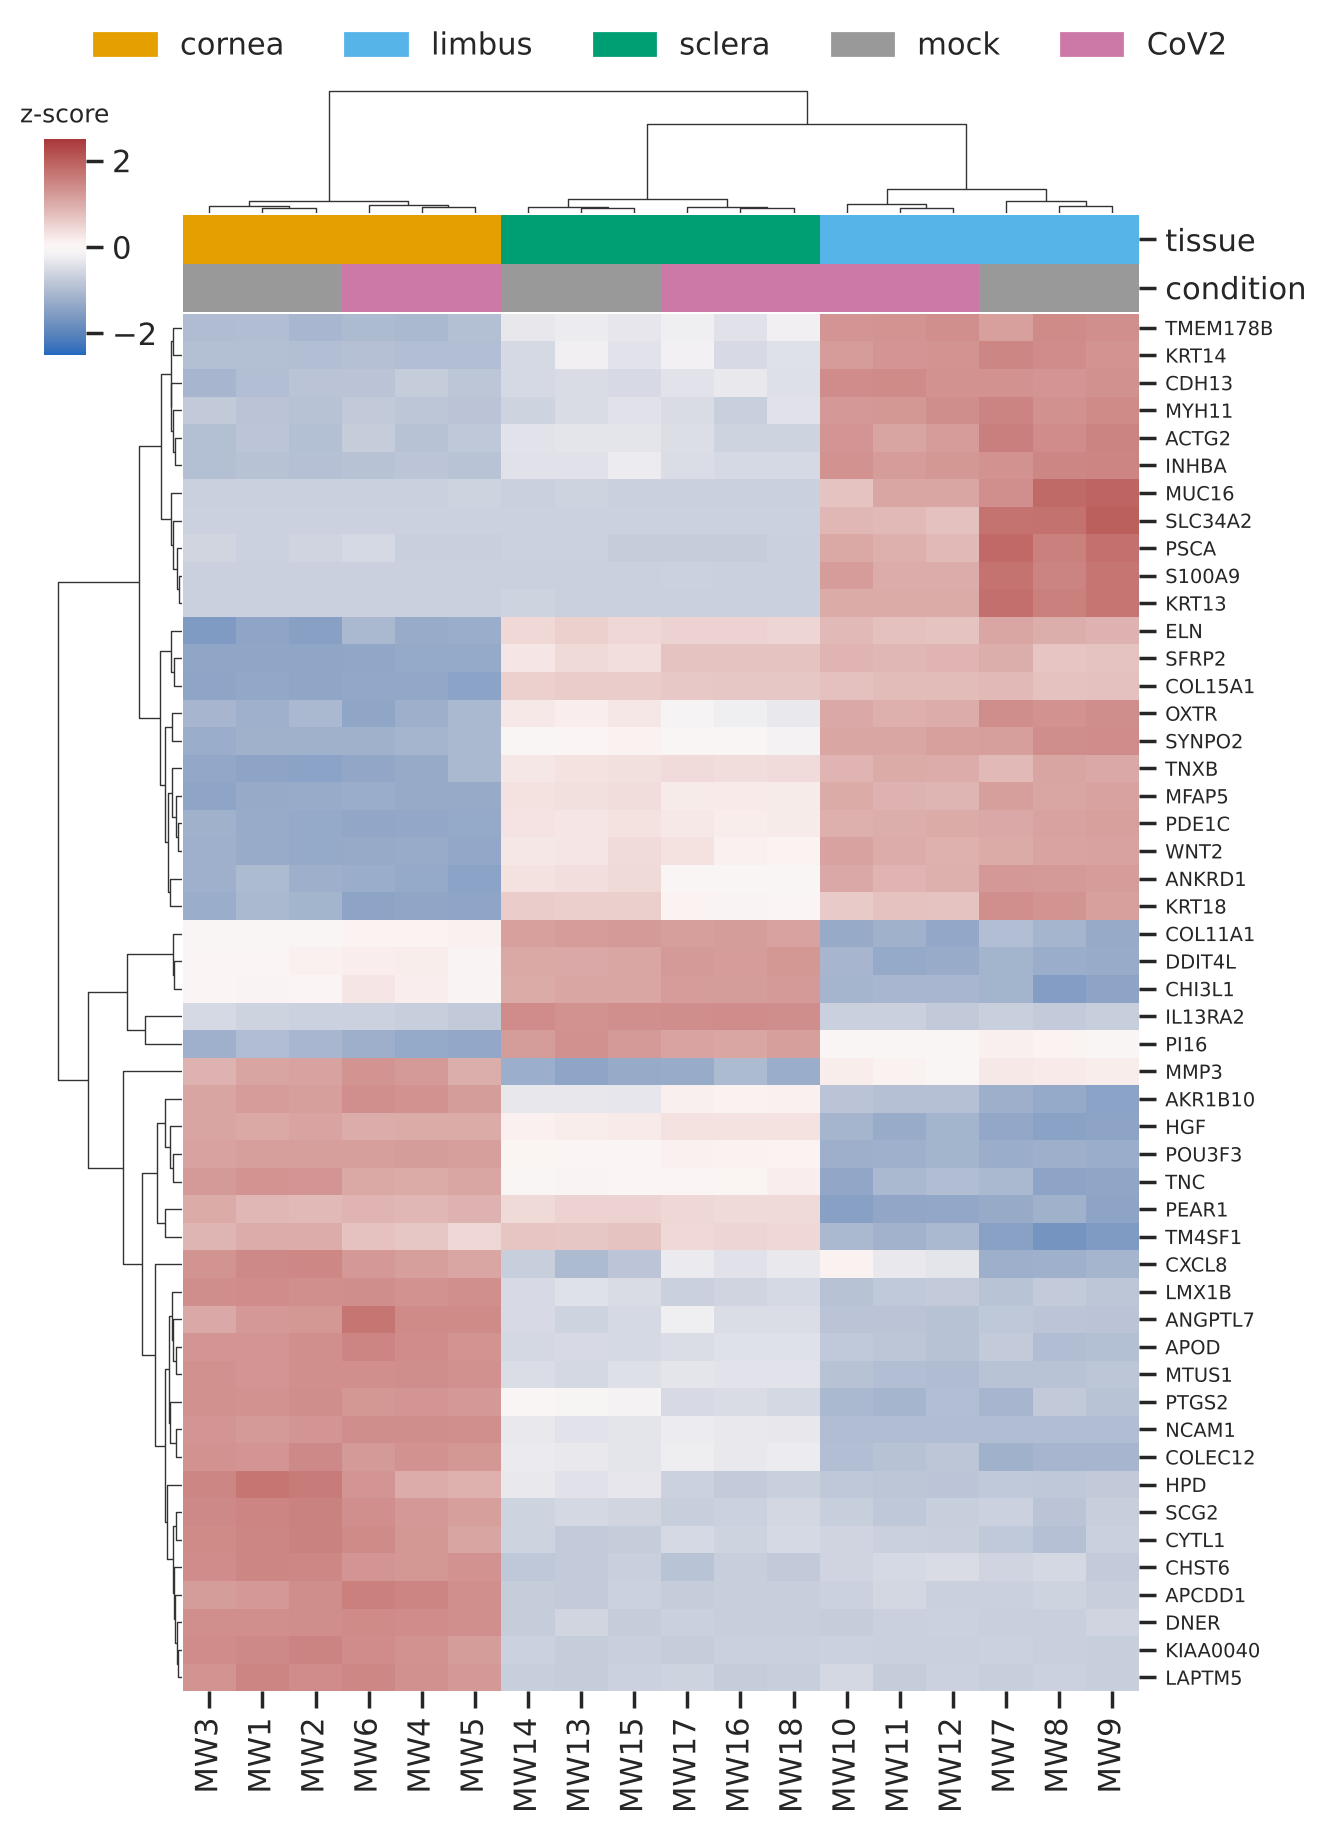

In [35]:
# Step 2 – clustermap is made of several Axes (g.ax_heatmap, g.ax_cbar, g.ax_col_dendrogram...): customise each
g.ax_cbar.set_title("z-score", fontsize=9)
g.ax_heatmap.set(xlabel="", ylabel="")
g.ax_heatmap.tick_params(axis="y", labelsize=7)

# Legends for the colour bars (clustermap does not make them automatically)
handles = [Patch(color=c, label=k) for k, c in {**TISSUE_COLORS, **CONDITION_COLORS}.items()]
g.ax_col_dendrogram.legend(handles=handles, ncol=5, loc="center", bbox_to_anchor=(0.5, 1.3), frameon=False)
g.figure

### ✏️ Exercise 4 – Heatmap of the top DE genes

Draw a clustered heatmap of the **30 most significant DE genes** (smallest `padj` in `de`) across **cornea samples only**.

*Hints:* `de.nsmallest(30, "padj").index` gives the genes; select cornea samples from `meta`.
Keep `z_score=0` and a diverging colour map. The CoV2 and mock samples separate perfectly – is that a *finding*?

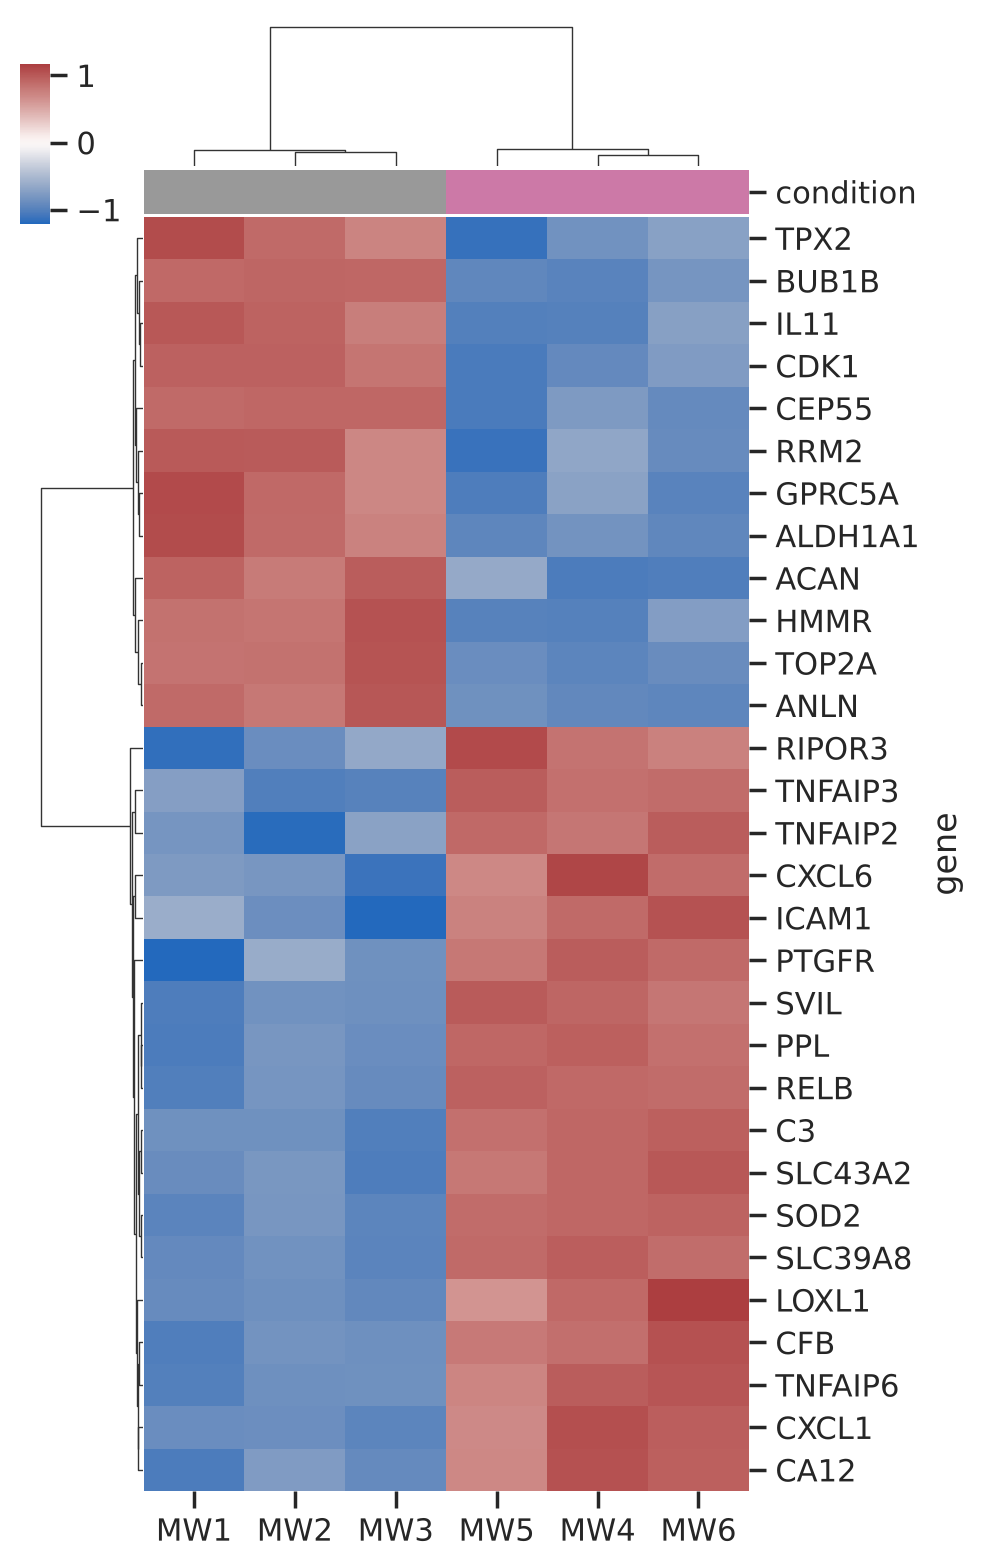

In [36]:
# Step 1 – the clustered heatmap
genes30 = de.nsmallest(30, "padj").index
cornea_samples = meta.loc[meta["tissue"] == "cornea", "sample"]

g = sns.clustermap(expr.loc[genes30, cornea_samples], z_score=0, cmap="vlag", center=0,
                   col_colors=col_colors.loc[cornea_samples, ["condition"]],
                   figsize=(5, 8), yticklabels=True,
                   dendrogram_ratio=(0.15, 0.1), cbar_pos=(0.02, 0.85, 0.03, 0.1))
plt.show()

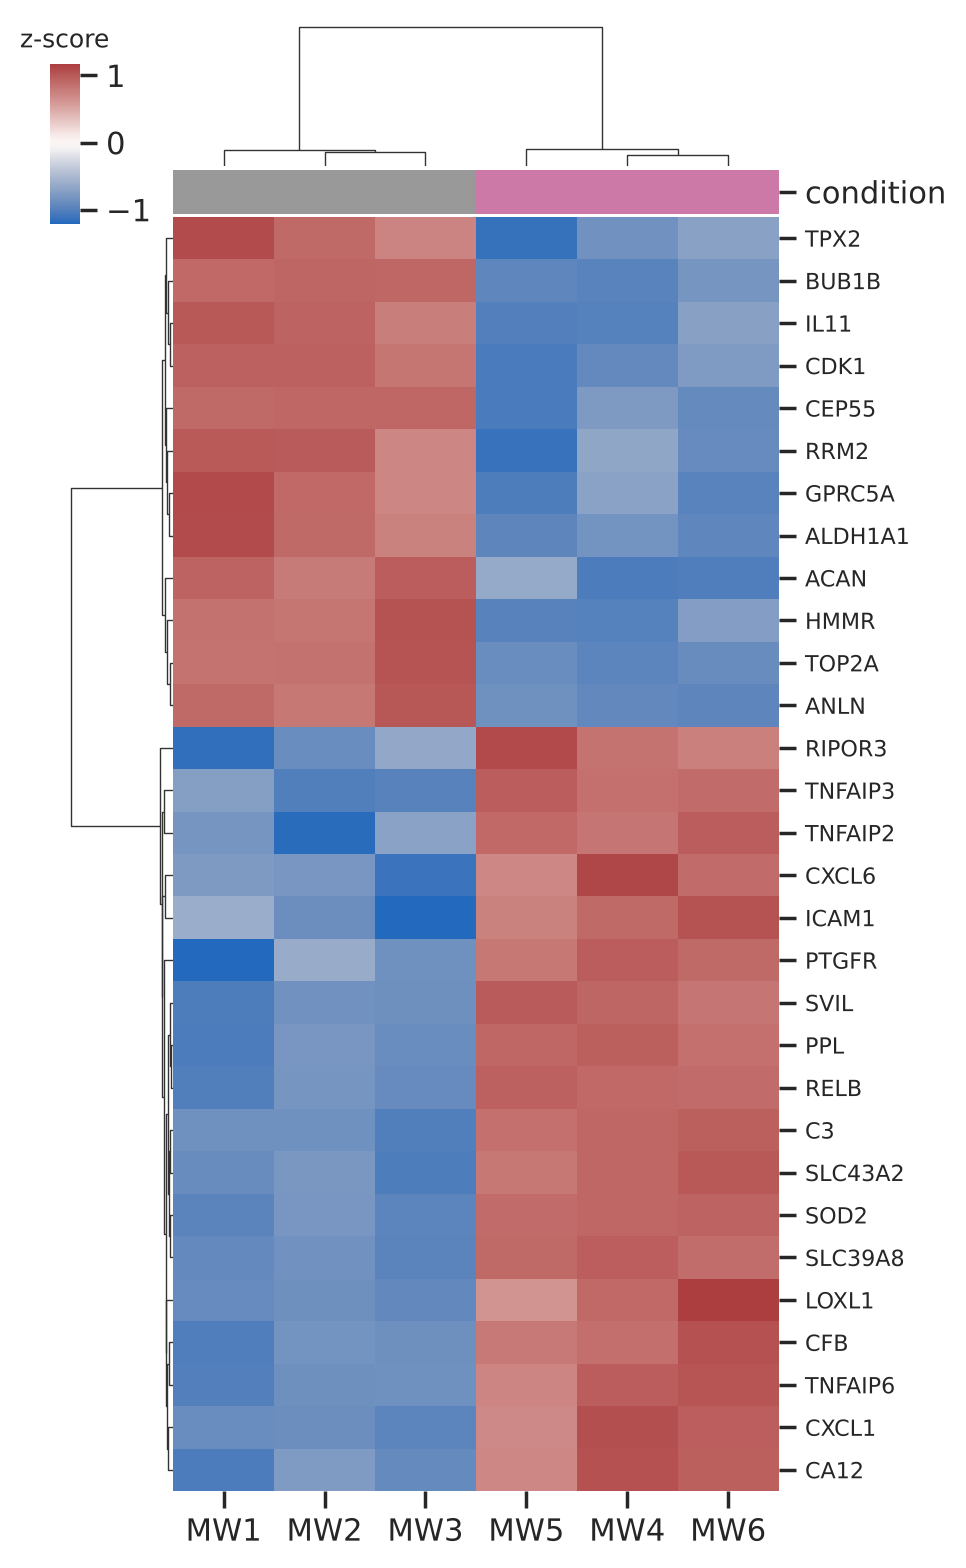

In [37]:
# Step 2 – colour-bar title and tidier labels
g.ax_cbar.set_title("z-score", fontsize=9)
g.ax_heatmap.tick_params(axis="y", labelsize=8)
g.ax_heatmap.set(xlabel="", ylabel="")
g.figure
# The perfect split is NOT evidence: we selected these 30 genes *because* they differ between CoV2 and mock,
# so they will always separate the groups (circular analysis). Such a heatmap illustrates the DE result;
# an unbiased view (e.g. top *variable* genes, or PCA) is needed to show that groups separate.

---
## Module 5 – Dimensionality reduction: PCA, t-SNE and UMAP

Each sample is described by thousands of genes – far too many dimensions to plot. Dimensionality reduction
squeezes this into **2 coordinates** that we can put on a scatter plot. We won't go into the maths, just what each
method is good for:

| Method | Idea | Read it as… | Watch out |
|---|---|---|---|
| **PCA** | linear; finds the directions of largest variance | Axes have a meaning (% variance explained); distances are (approximately) interpretable | Can miss non-linear structure |
| **t-SNE** | non-linear; keeps each point's nearest neighbours close | Good at revealing clusters | Cluster sizes & distances *between* clusters mean little; depends on `perplexity` and the random seed |
| **UMAP** | non-linear; similar goal to t-SNE, faster | Clusters + somewhat better global layout | Depends on `n_neighbors`, `min_dist`, random seed |

> ⚠️ t-SNE/UMAP are designed for thousands of points (e.g. single cells). With 18 samples they work but are fragile –
> PCA is the standard choice for bulk RNA-seq. We show all three so you can recognise them.

Note that these functions expect **samples as rows** and **features (genes) as columns**, so we transpose.

In [38]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

X = expr.loc[expr.var(axis=1).nlargest(500).index].T     # 18 samples x 500 genes

pca = PCA(n_components=2).fit(X)
pcs = pca.transform(X)
var_exp = pca.explained_variance_ratio_ * 100

tsne_xy = TSNE(n_components=2, perplexity=5, random_state=42).fit_transform(X)
umap_xy = umap.UMAP(n_neighbors=5, min_dist=0.3, random_state=42, n_jobs=1).fit_transform(X)

emb = meta.set_index("sample").loc[X.index].copy()
emb[["PC1", "PC2"]] = pcs
emb[["tSNE1", "tSNE2"]] = tsne_xy
emb[["UMAP1", "UMAP2"]] = umap_xy
emb.head()

,tissue,condition,PC1,PC2,tSNE1,tSNE2,UMAP1,UMAP2
MW1,cornea,mock,34.685887,-10.783242,10.150601,-106.184029,0.789415,-2.700684
MW2,cornea,mock,35.745606,-11.011882,21.617222,-117.000435,1.169571,-3.110659
MW3,cornea,mock,35.404355,-11.146010,34.815712,-92.528770,1.420141,-2.581552
MW4,cornea,CoV2,35.115962,-10.047049,36.846416,-109.444786,0.478312,-3.587900
MW5,cornea,CoV2,34.116443,-10.047647,24.922941,-102.645340,0.729966,-4.125525


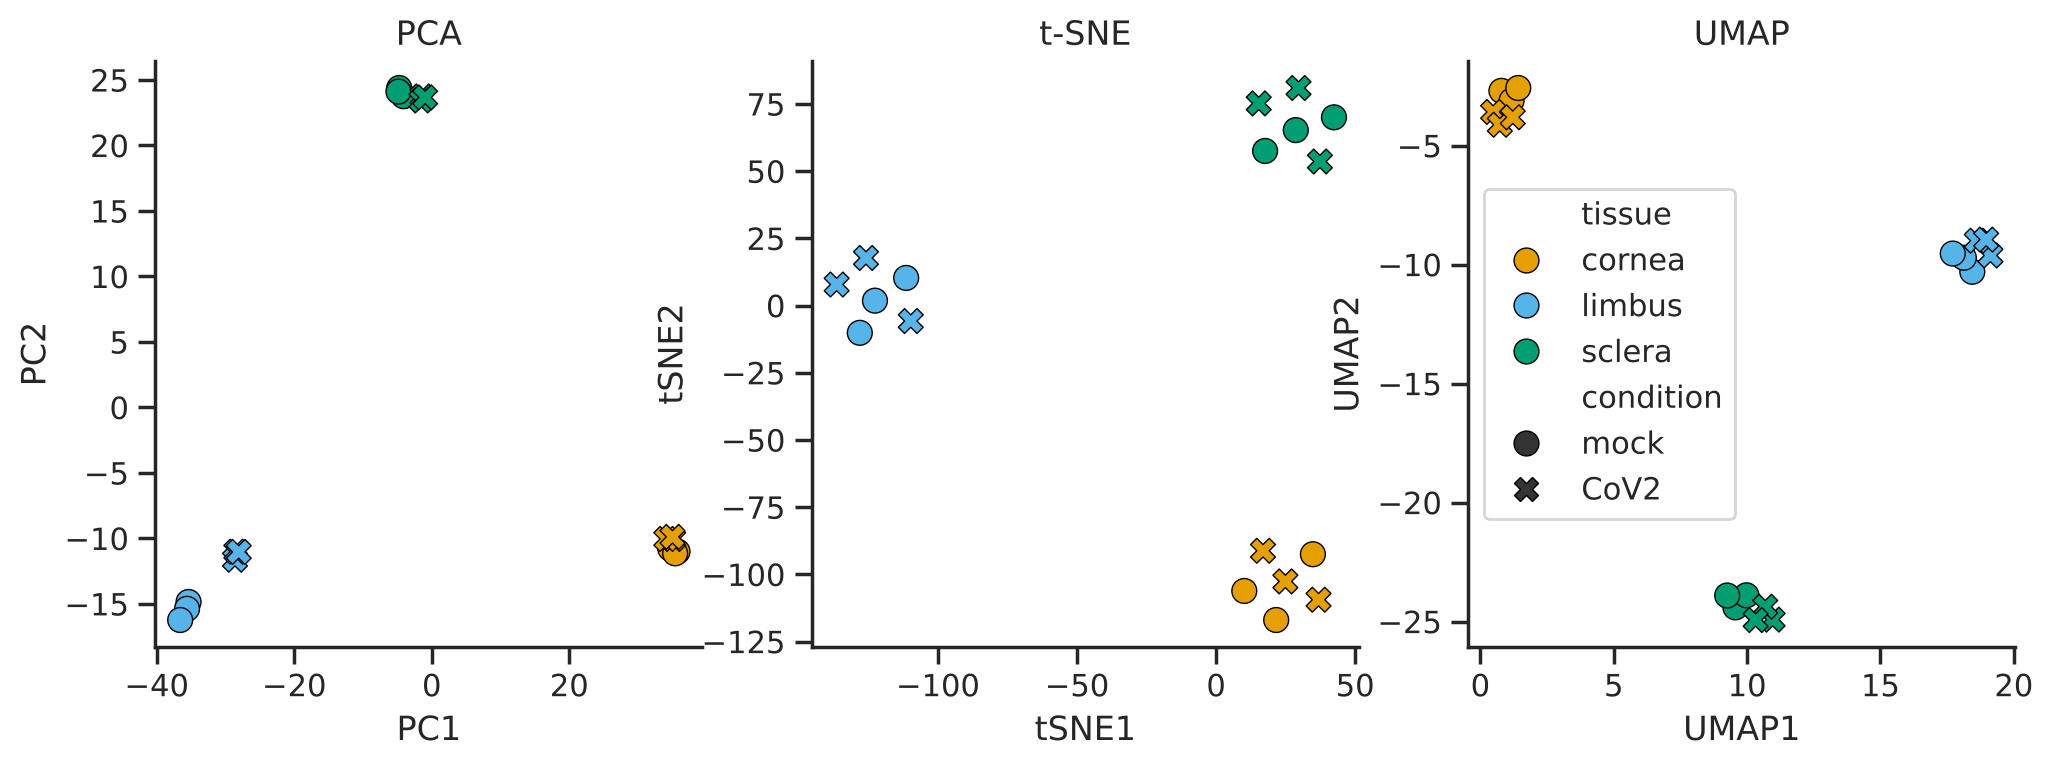

In [39]:
# Step 1 – three Axes, one scatter plot per method (hue = tissue, marker style = condition)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
panels = [("PC1", "PC2", "PCA"), ("tSNE1", "tSNE2", "t-SNE"), ("UMAP1", "UMAP2", "UMAP")]

for ax, (x, y, title) in zip(axes, panels):
    sns.scatterplot(data=emb, x=x, y=y, hue="tissue", style="condition", palette=TISSUE_COLORS,
                    hue_order=TISSUE_ORDER, style_order=CONDITION_ORDER, s=80,
                    edgecolor="black", linewidth=0.5, ax=ax, legend=(ax is axes[-1]))
    ax.set_title(title)
plt.show()

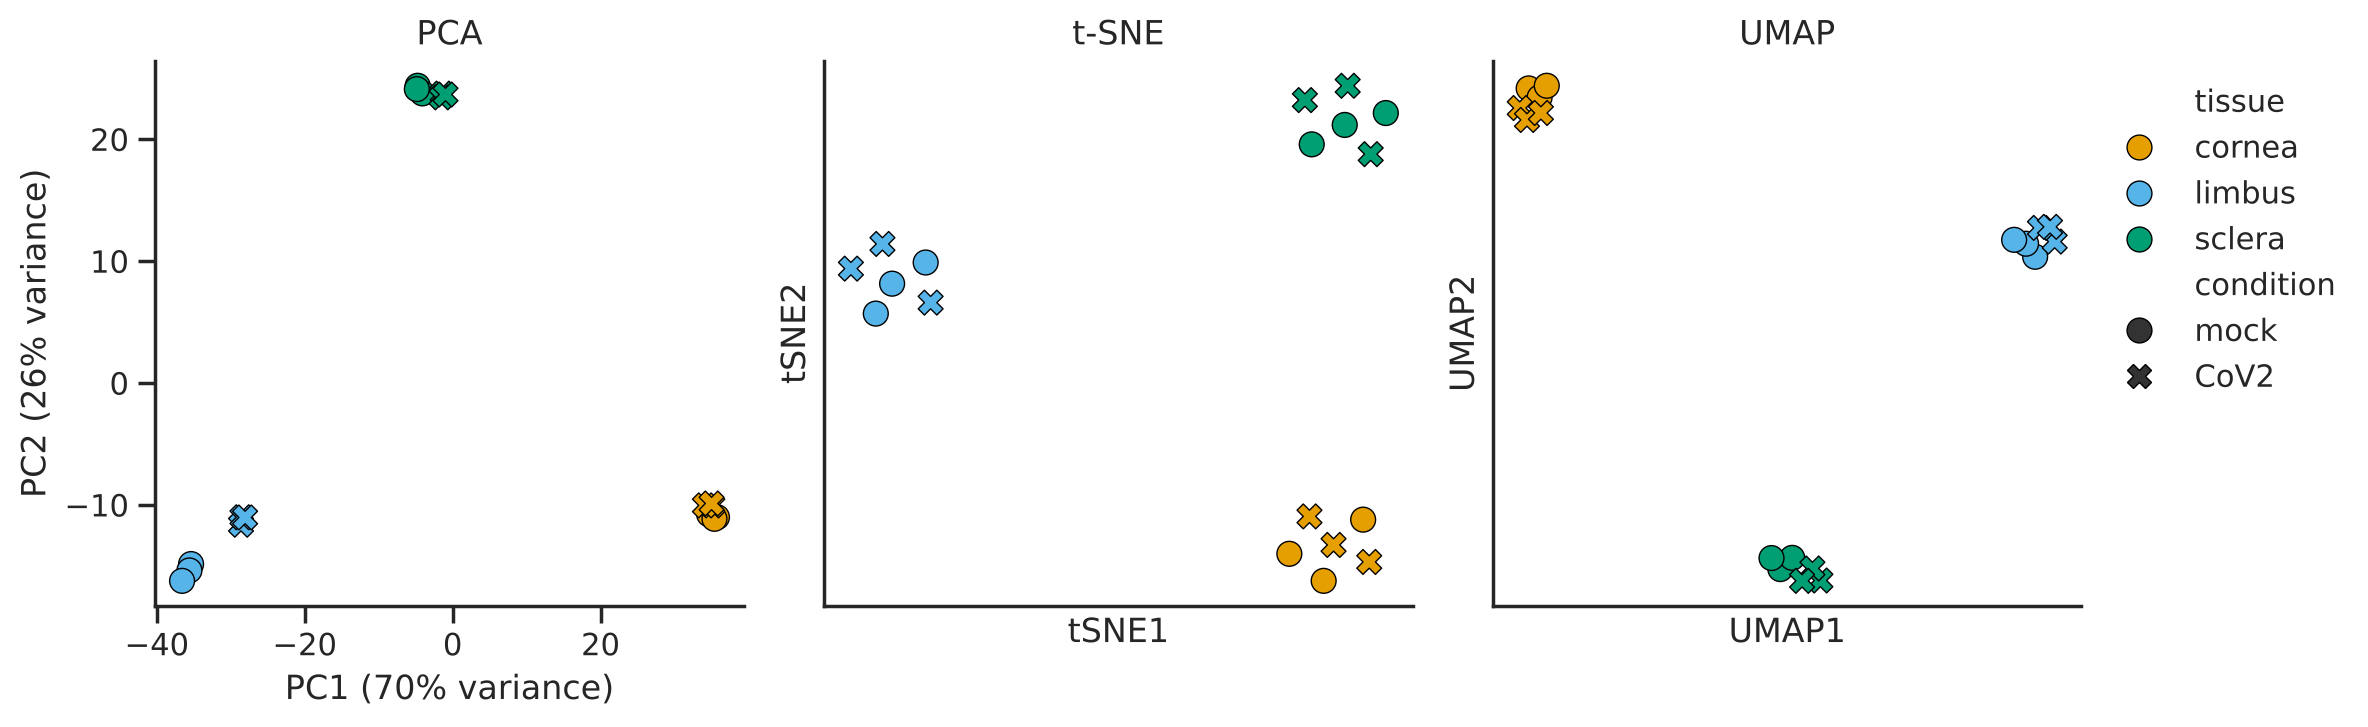

In [40]:
# Step 2 – PCA axes get "% variance explained"; t-SNE/UMAP coordinates have no units, so hide their ticks
axes[0].set(xlabel=f"PC1 ({var_exp[0]:.0f}% variance)", ylabel=f"PC2 ({var_exp[1]:.0f}% variance)")
for ax in axes[1:]:
    ax.set(xticks=[], yticks=[])
sns.move_legend(axes[-1], "upper left", bbox_to_anchor=(1, 1), frameon=False)
fig.tight_layout()
fig

> 💡 Using **colour for one variable and marker shape for another** (`hue=` + `style=`) lets one panel show the full
> design. **Tissue dominates both PC1 and PC2** (96% of the variance together) – the infection effect is much smaller
> and is hidden here. To see it, look *within* one tissue at a time:

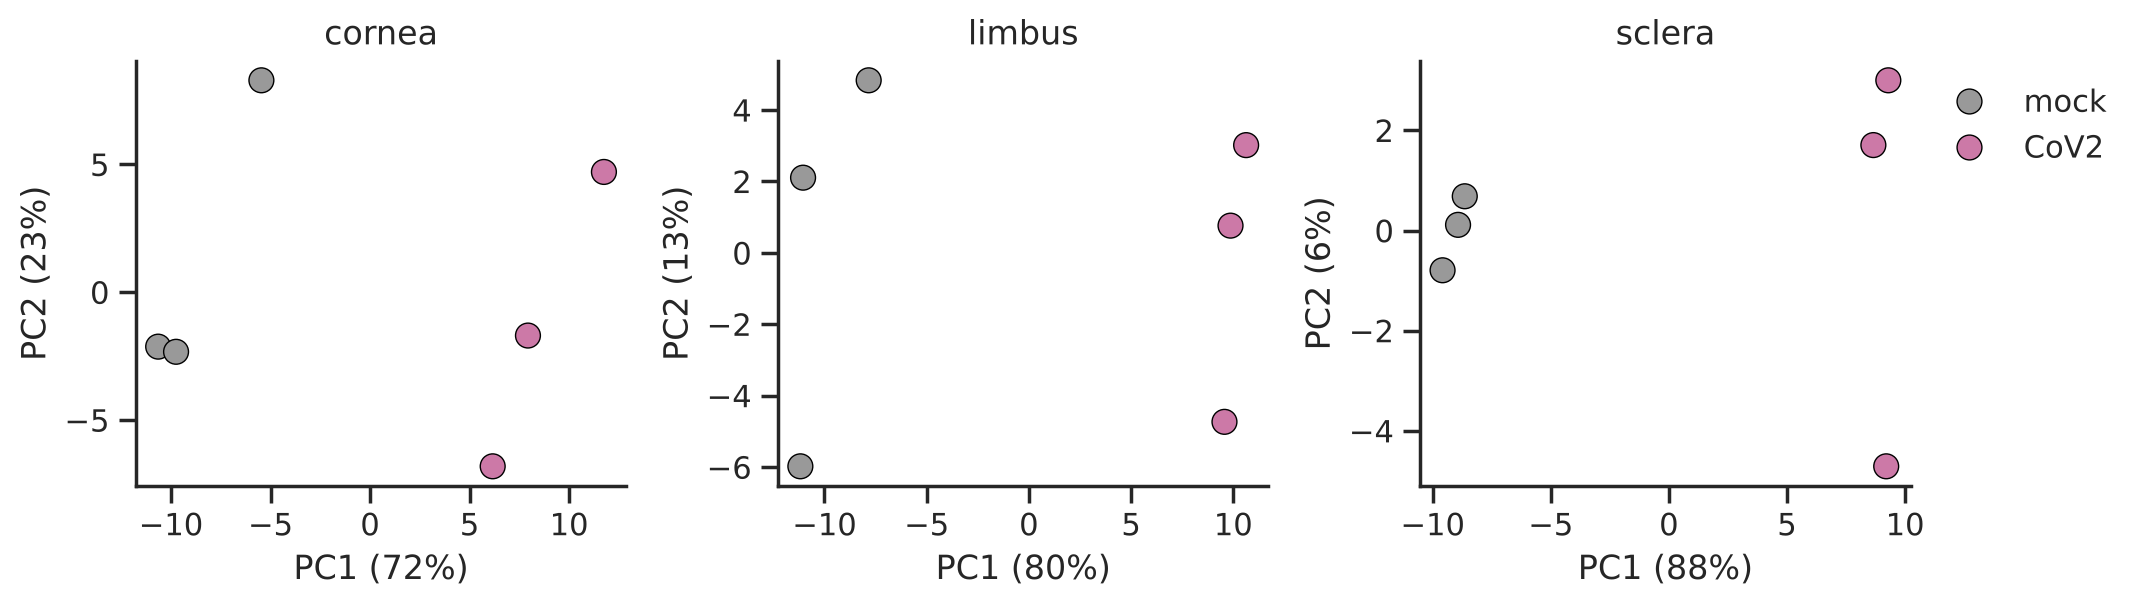

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, tissue in zip(axes, TISSUE_ORDER):
    s = meta.loc[meta["tissue"] == tissue, "sample"]
    Xt = expr.loc[expr[s].var(axis=1).nlargest(500).index, s].T      # top 500 variable genes in this tissue
    p = PCA(n_components=2).fit(Xt)
    xy = p.transform(Xt)
    sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=meta.set_index("sample").loc[s, "condition"].values,
                    palette=CONDITION_COLORS, s=80, edgecolor="black", linewidth=0.5, ax=ax, legend=(tissue == "sclera"))
    ax.set(title=tissue, xlabel=f"PC1 ({p.explained_variance_ratio_[0]:.0%})",
           ylabel=f"PC2 ({p.explained_variance_ratio_[1]:.0%})")
sns.move_legend(axes[-1], "upper left", bbox_to_anchor=(1, 1), frameon=False)
plt.tight_layout()
plt.show()

> 💡 Within each tissue, **PC1 separates CoV2 from mock**. What you put into a PCA (which samples, which genes) decides
> which story it can tell – say so in the figure legend.

### ✏️ Exercise 5 – How sensitive is t-SNE? *(optional – can be a quick live demo)*

Re-run t-SNE with `perplexity` = 2, 5 and 12 and plot the three results side by side (coloured by tissue).
Does the picture change? What would you report in a paper's Methods section so others can reproduce your plot?

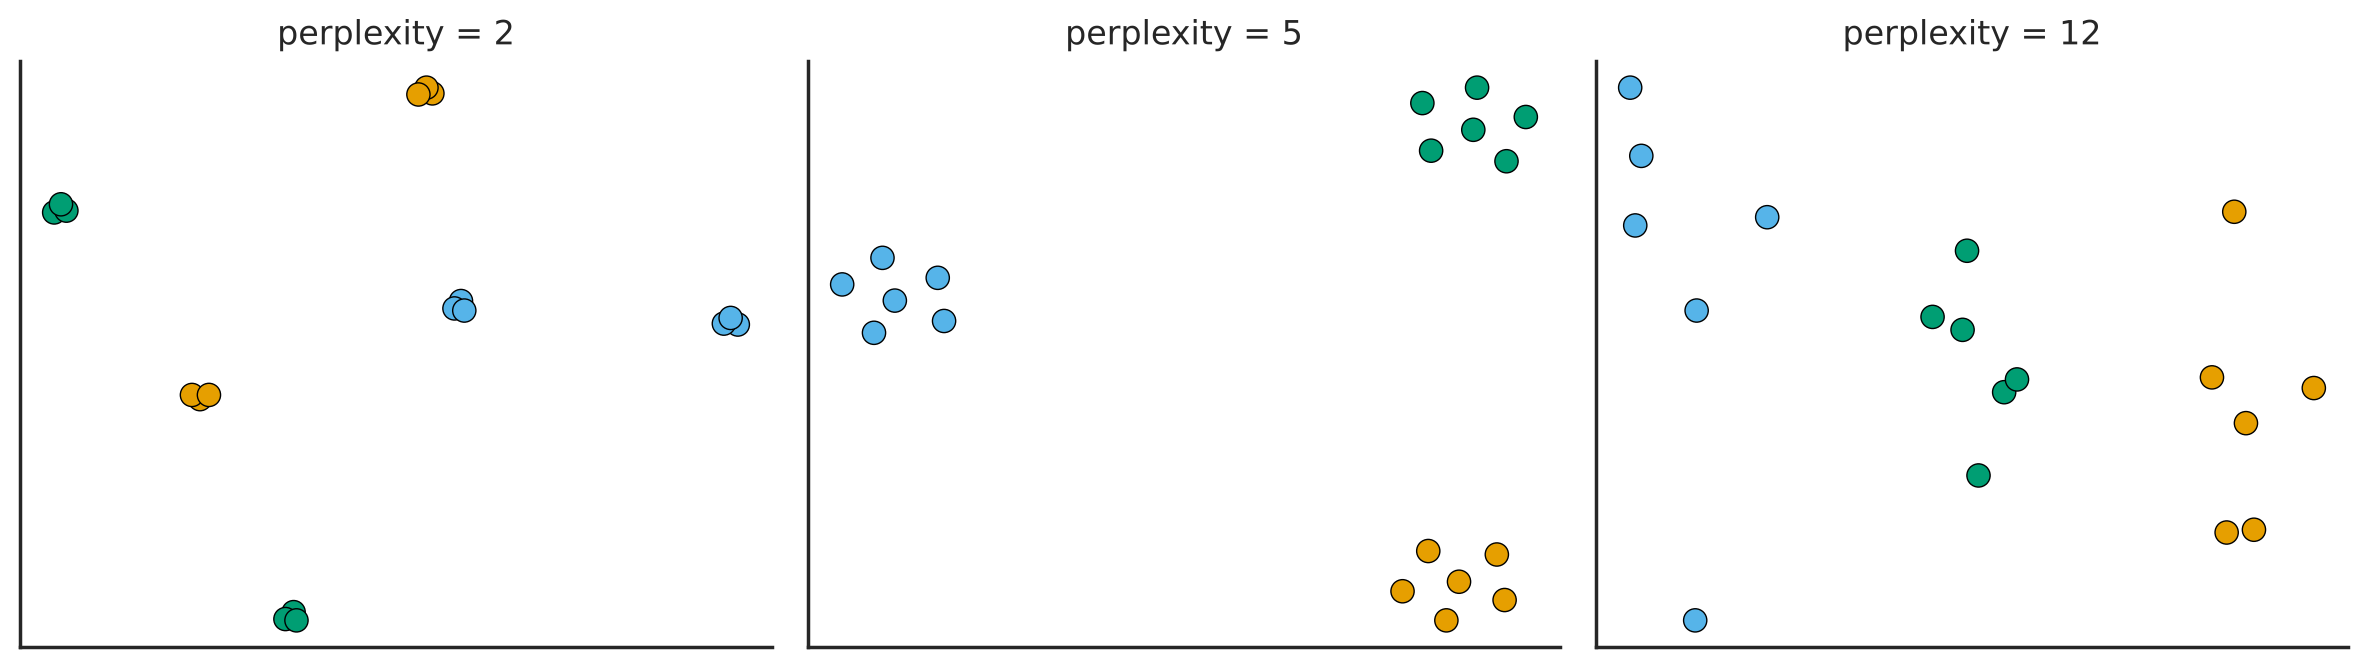

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, perp in zip(axes, [2, 5, 12]):
    xy = TSNE(n_components=2, perplexity=perp, random_state=42).fit_transform(X)
    sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=emb["tissue"].values, palette=TISSUE_COLORS,
                    s=70, edgecolor="black", linewidth=0.5, ax=ax, legend=False)
    ax.set(title=f"perplexity = {perp}", xticks=[], yticks=[])
plt.tight_layout()
plt.show()
# The layout changes a lot with perplexity. Report: method, input features (top 500 variable genes,
# log2 CPM), perplexity / n_neighbors, and the random seed.

---
## Module 6 – Multi-panel figures & high-resolution export

Journals want figures at an exact **physical size** (typically ~85 mm for one column, ~180 mm for two) with
**readable fonts** (≥ 6 pt at final size, usually Arial/Helvetica) and **panel labels** (A, B, C…). The workflow:

1. Define a *paper* style once (font family and sizes, line widths, export settings).
2. Create the layout with `plt.subplot_mosaic` – panels are named, so the layout is easy to read and change.
3. Draw each panel with **axes-level** functions (`ax=...`).
4. Add panel labels and save as **vector** (PDF/SVG) for editing in Inkscape, plus a high-dpi PNG.

We switch to the paper style with `plt.rcParams.update(PAPER)`. It applies to **every figure created from now on**
(Module 6 is the last plotting module, so earlier plots are not affected).

In [43]:
MM = 1 / 25.4                       # millimetres -> inches

PAPER = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],   # first one installed wins
    "mathtext.fontset": "custom", "mathtext.rm": "sans", "mathtext.it": "sans:italic",  # math text ($...$)
    "mathtext.bf": "sans:bold", "mathtext.sf": "sans", "mathtext.cal": "sans",          # in the same font
    "font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7,
    "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "pdf.fonttype": 42,              # embed real fonts: text stays editable in Inkscape/Illustrator
    "svg.fonttype": "none",          # keep text as text (not paths) in SVG
}
plt.rcParams.update(PAPER)

#### Step 1 – the empty layout

Letters name the panels; `;` separates rows, and a repeated letter makes a panel span several cells (e.g. `"AB;CC"`).
We add the bold panel labels straight away, so you can see which Axes is which.

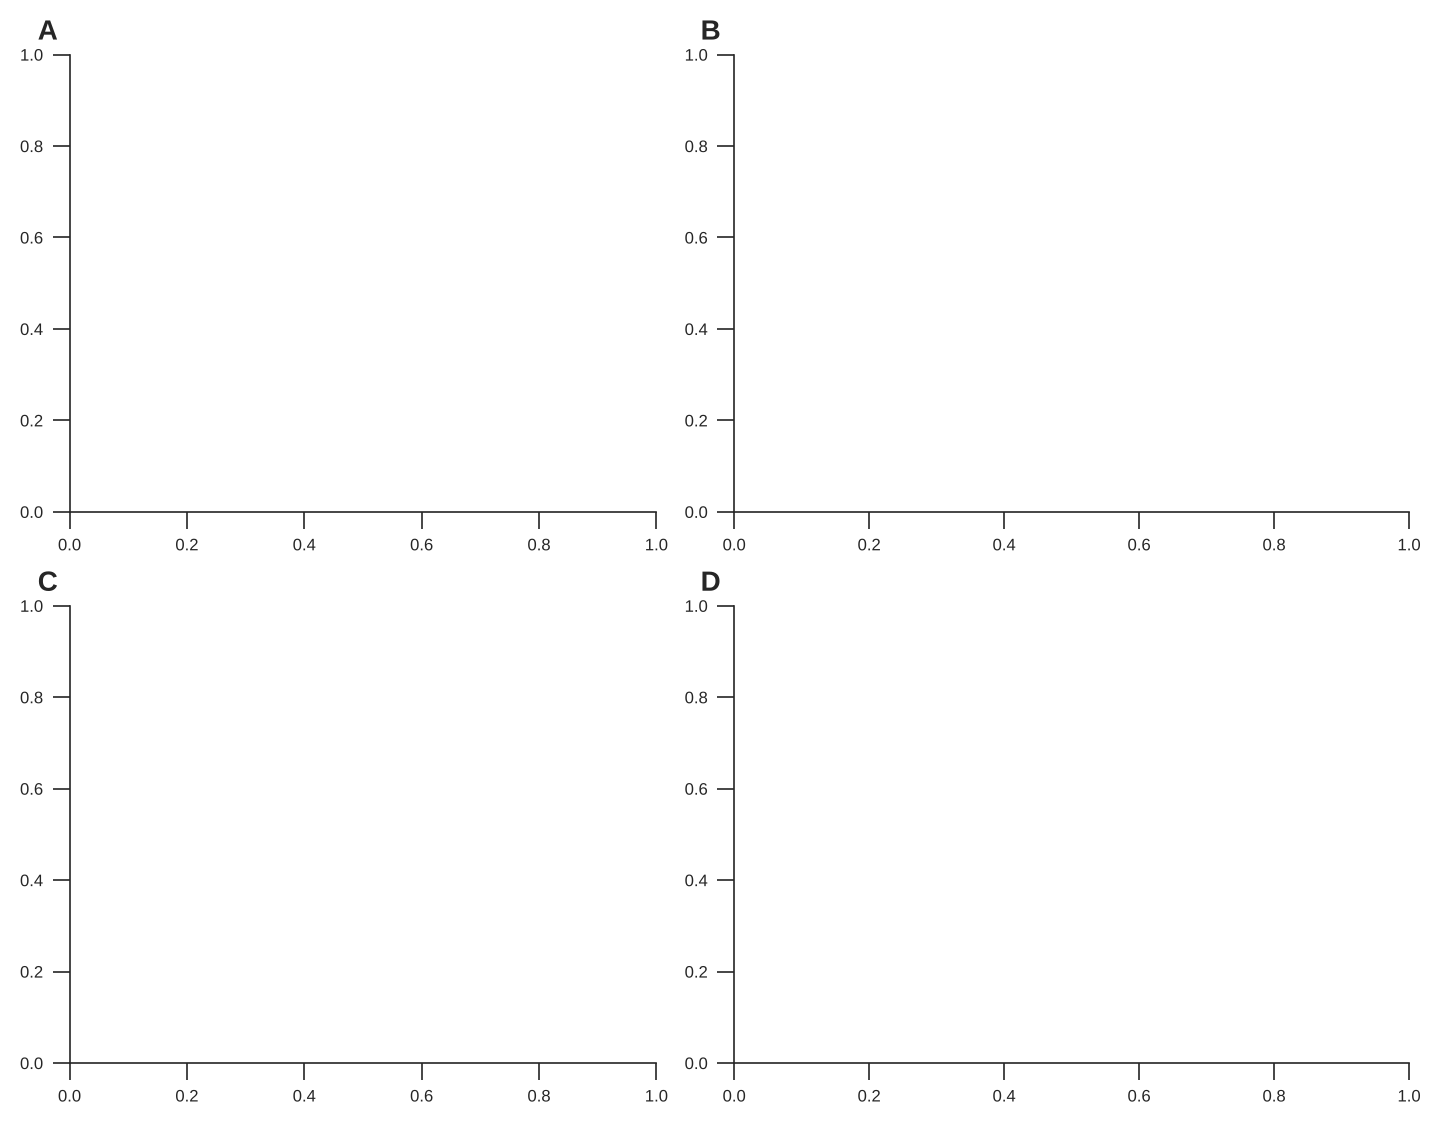

In [44]:
fig, axd = plt.subplot_mosaic("AB;CD", figsize=(180 * MM, 140 * MM), layout="constrained",
                              gridspec_kw={"width_ratios": [1, 1.15]})

for label, ax in axd.items():                 # axd is a dictionary: {"A": Axes, "B": Axes, ...}
    ax.text(-0.02, 1.02, label, transform=ax.transAxes, fontsize=10, fontweight="bold",
            ha="right", va="bottom")
plt.show()

#### Steps 2–5 – fill the panels one at a time

Each cell draws on one Axes of the same `fig`; watch how `layout="constrained"` rearranges the panels as content is added.

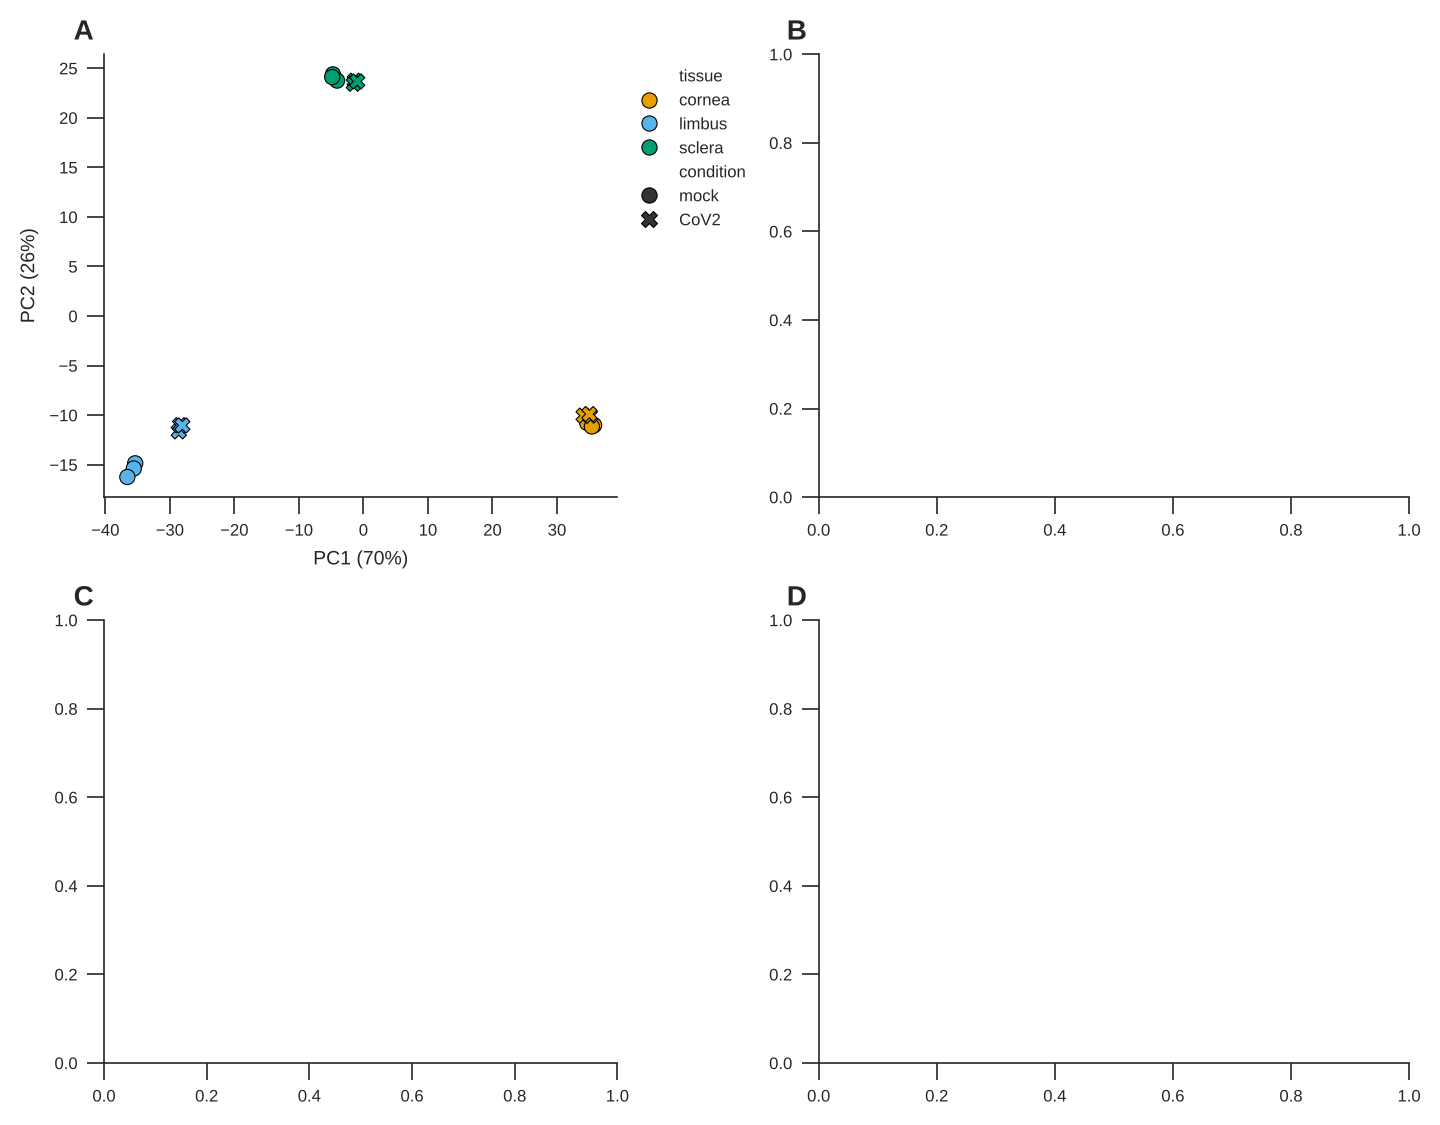

In [45]:
# Step 2 – panel A: PCA
ax = axd["A"]
sns.scatterplot(data=emb, x="PC1", y="PC2", hue="tissue", style="condition", palette=TISSUE_COLORS,
                hue_order=TISSUE_ORDER, style_order=CONDITION_ORDER, s=30, edgecolor="black",
                linewidth=0.4, ax=ax)
ax.set(xlabel=f"PC1 ({var_exp[0]:.0f}%)", ylabel=f"PC2 ({var_exp[1]:.0f}%)")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), frameon=False, title=None)
fig

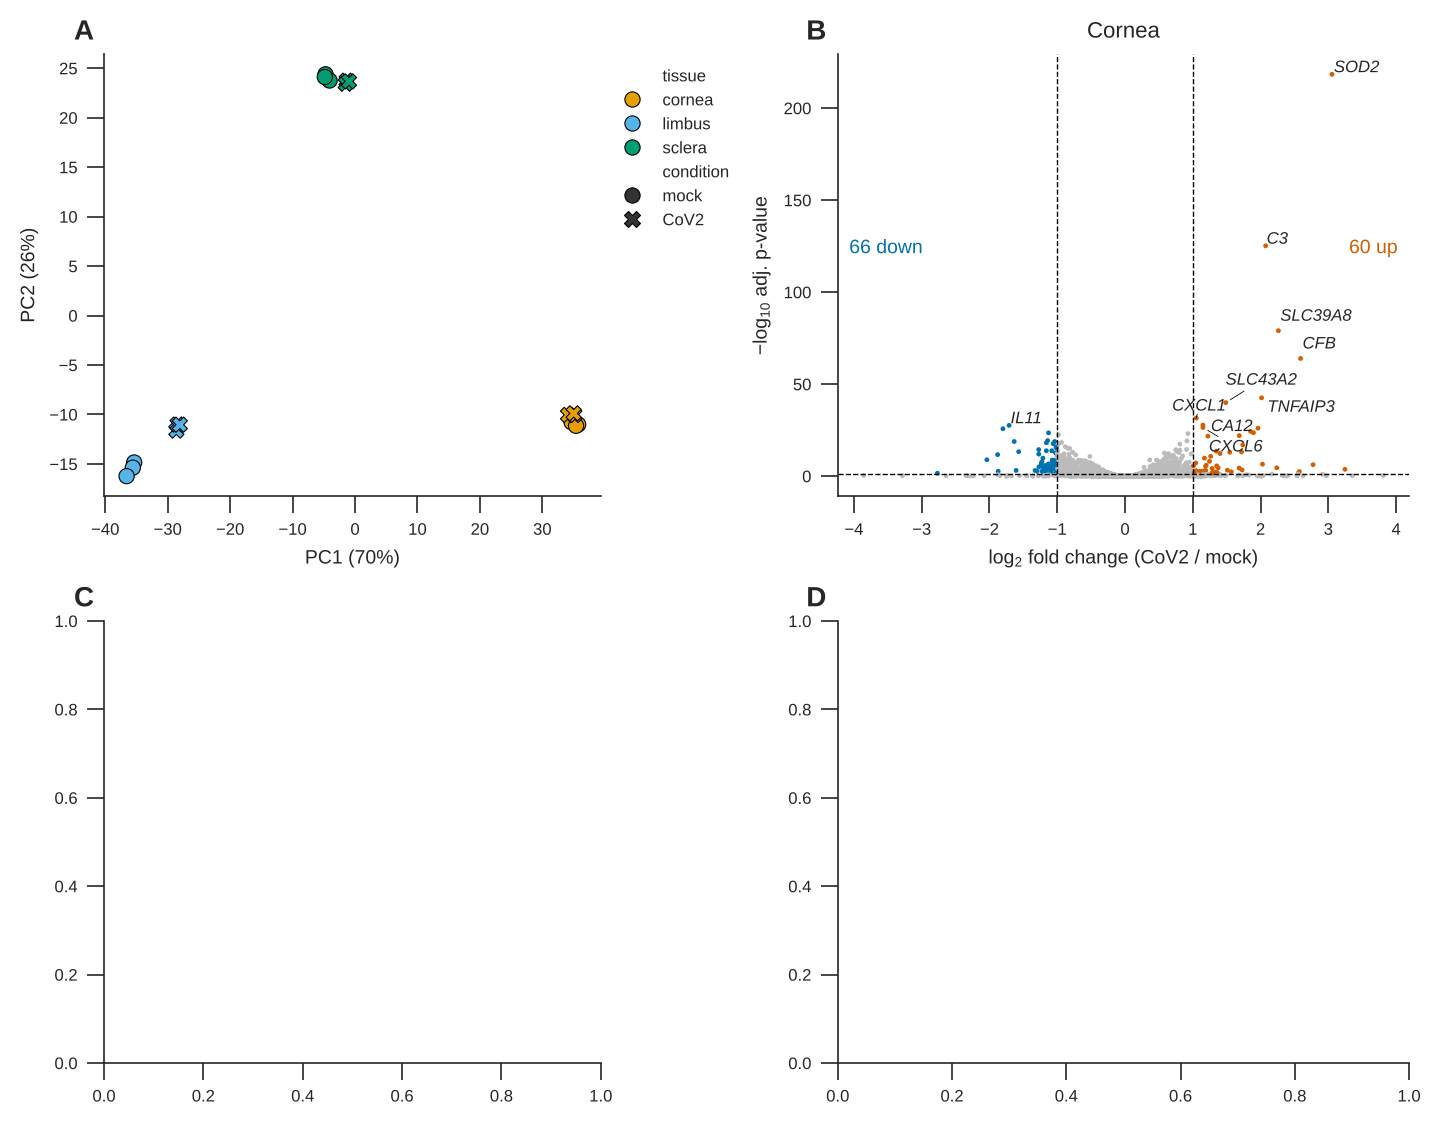

In [46]:
# Step 3 – panel B: volcano plot (same recipe as Module 3, with smaller points and fonts)
ax = axd["B"]
sns.scatterplot(data=de, x="log2FoldChange", y="neg_log10_padj", hue="status", palette=DE_COLORS,
                hue_order=list(DE_COLORS), s=3, linewidth=0, rasterized=True, legend=False, ax=ax)
ax.axhline(-np.log10(PADJ), color="black", ls="--", lw=0.5)
for x in (-LFC, LFC):
    ax.axvline(x, color="black", ls="--", lw=0.5)
texts = [ax.text(r.log2FoldChange, r.neg_log10_padj, g, fontsize=6, fontstyle="italic")
         for g, r in top.iterrows()]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="black", lw=0.3))
n_up, n_down = (de.status == "up in CoV2").sum(), (de.status == "down in CoV2").sum()
ax.text(0.98, 0.55, f"{n_up} up", color=DE_COLORS["up in CoV2"], ha="right", transform=ax.transAxes)
ax.text(0.02, 0.55, f"{n_down} down", color=DE_COLORS["down in CoV2"], transform=ax.transAxes)
ax.set(xlabel="log$_2$ fold change (CoV2 / mock)", ylabel="−log$_{10}$ adj. p-value", title="Cornea")
fig

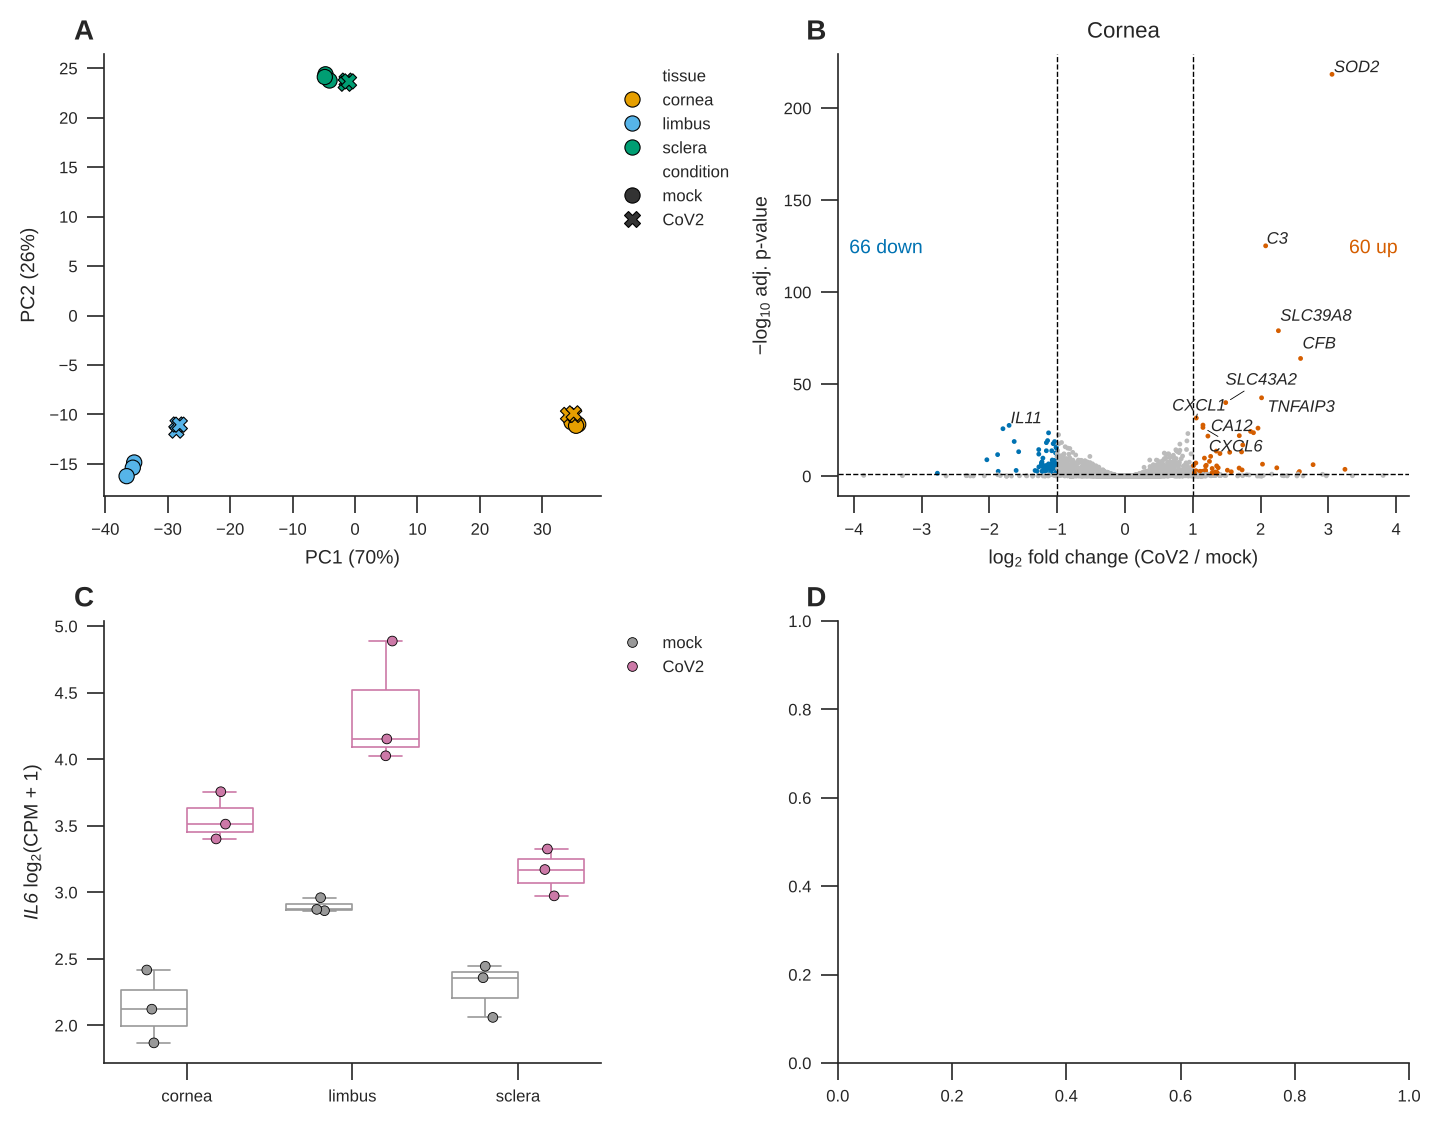

In [47]:
# Step 4 – panel C: one gene across tissues, box + points
ax = axd["C"]
df_gene = expr_long[expr_long["gene"] == "IL6"]
sns.boxplot(data=df_gene, x="tissue", y="log2cpm", hue="condition", palette=CONDITION_COLORS,
            order=TISSUE_ORDER, fill=False, showfliers=False, linewidth=0.6, ax=ax, legend=False)
sns.stripplot(data=df_gene, x="tissue", y="log2cpm", hue="condition", palette=CONDITION_COLORS,
              order=TISSUE_ORDER, dodge=True, size=3.5, edgecolor="black", linewidth=0.3, ax=ax)
ax.set(xlabel="", ylabel="$\\it{IL6}$ log$_2$(CPM + 1)")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), frameon=False, title=None)
fig

`sns.clustermap` makes its own figure, so it can't go inside our layout. For panel D we **cluster the genes ourselves**
(with SciPy) and draw an ordinary `sns.heatmap`.

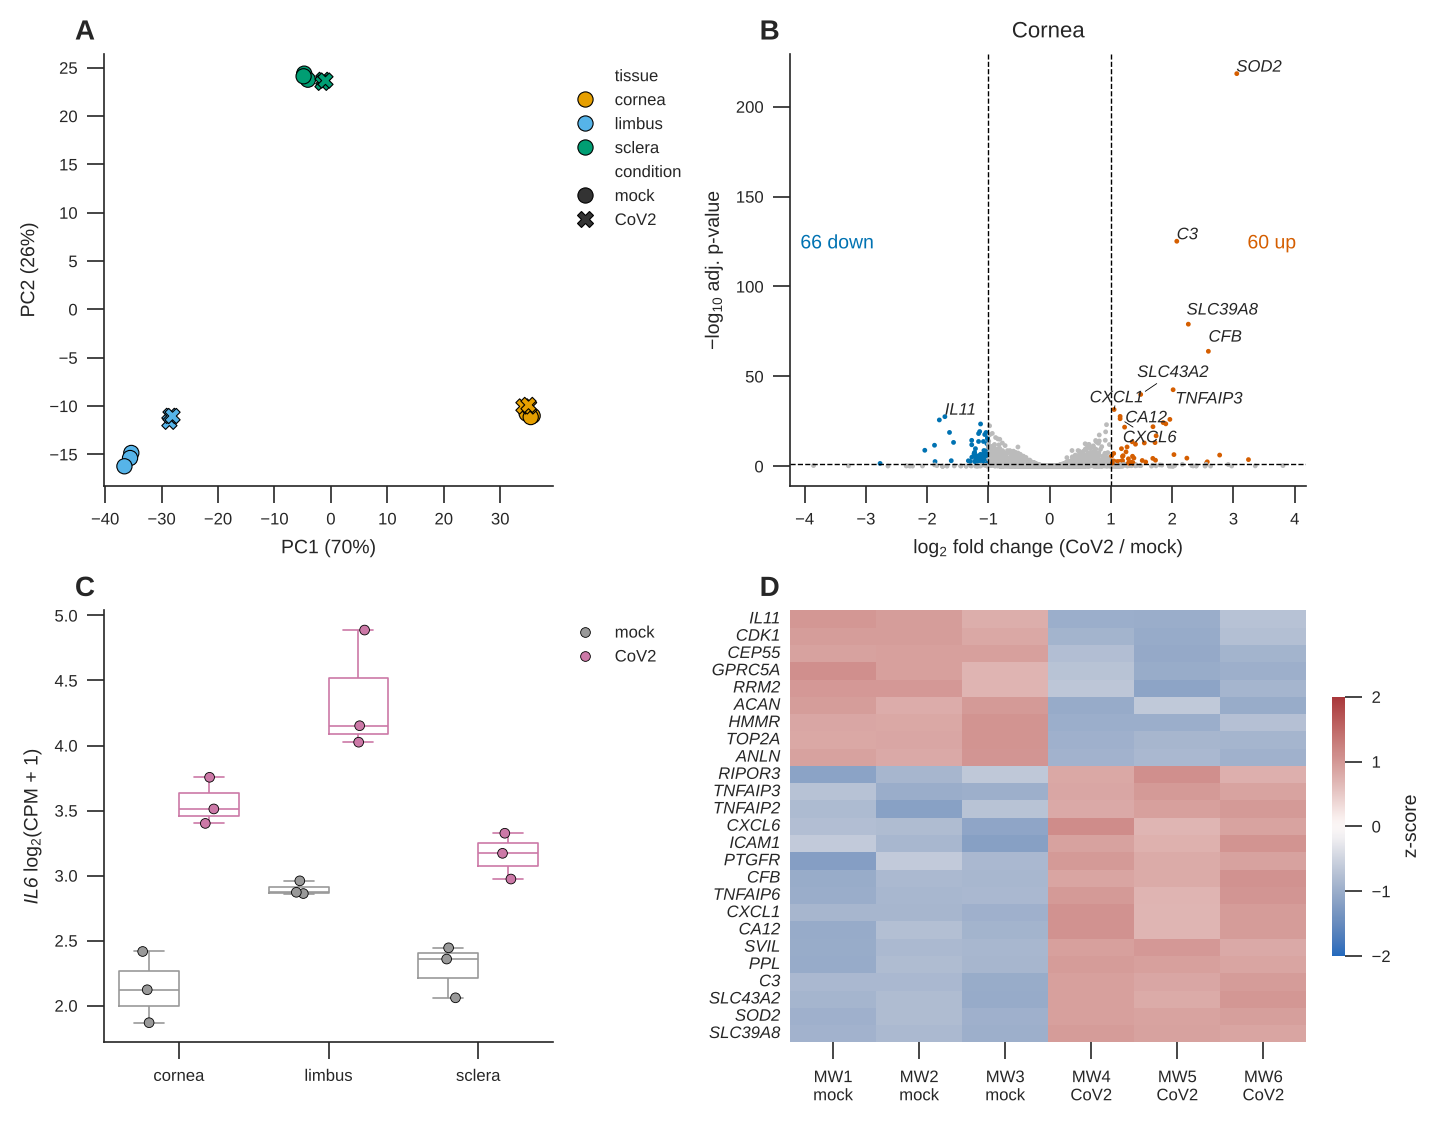

In [48]:
# Step 5 – panel D: heatmap of the top DE genes, clustered by hand
from scipy.cluster.hierarchy import linkage, leaves_list

ax = axd["D"]
genes = de.nsmallest(25, "padj").index
cornea = meta.query("tissue == 'cornea'").sort_values("condition", ascending=False)["sample"]
mat = expr.loc[genes, cornea]
mat = mat.sub(mat.mean(axis=1), axis=0).div(mat.std(axis=1), axis=0)     # z-score per gene
mat = mat.iloc[leaves_list(linkage(mat, method="average"))]               # cluster genes
sns.heatmap(mat, cmap="vlag", center=0, vmin=-2, vmax=2, ax=ax,
            cbar_kws={"label": "z-score", "shrink": 0.6})
ax.set(xlabel="", ylabel="")
ax.set_xticklabels([f"{s}\n{meta.set_index('sample').loc[s, 'condition']}" for s in cornea], rotation=0)
ax.tick_params(axis="y", labelsize=6, length=0)
for lab in ax.get_yticklabels():
    lab.set_fontstyle("italic")
fig

#### Step 6 – exporting

| Format | Use it for | Notes |
|---|---|---|
| **PDF / SVG** (vector) | Editing in Inkscape (Day 4), LaTeX (Day 5), journal submission | Infinitely scalable; text stays editable with the `fonttype` settings above |
| **PNG / TIFF** (raster) | Slides, web, journals that require raster | Typical journal minimums: **300 dpi** for photos, **600 dpi** for plots with text, **1000+ dpi** for pure line art – always check the author guidelines |

* We do **not** use `bbox_inches="tight"` for the journal export: it crops or grows the canvas, so the file would no
  longer be exactly 180 mm wide. `layout="constrained"` already keeps labels and legends inside the figure.
* Never take a screenshot of a plot for a paper!

In [49]:
fig.savefig(FIGS / "Figure1_cornea_CoV2.pdf")
fig.savefig(FIGS / "Figure1_cornea_CoV2.svg")
fig.savefig(FIGS / "Figure1_cornea_CoV2.png", dpi=600)

w, h = fig.get_size_inches() / MM
print(f"Exported at {w:.0f} x {h:.0f} mm:", sorted(p.name for p in FIGS.iterdir()))

Exported at 180 x 140 mm: ['Exercise6.pdf', 'Exercise6.png', 'Exercise6.svg', 'Figure1_cornea_CoV2.pdf', 'Figure1_cornea_CoV2.png', 'Figure1_cornea_CoV2.svg']


> ⚠️ **On Colab, the `figures/` folder is deleted when your session ends.** Run the cell below to download your files
> (or use the 📁 *Files* panel on the left). Keep `Figure1_cornea_CoV2.svg`/`.pdf` – you will polish it in **Inkscape on Day 4**.
>
> ✅ **Check your export:** open the PDF – is it 180 mm wide? Can you select the text? Are the dots of the volcano plot
> a single image (rasterised) while the axes stay sharp when you zoom in?

In [50]:
if using_colab:
    from google.colab import files
    for name in ["Figure1_cornea_CoV2.pdf", "Figure1_cornea_CoV2.svg"]:
        files.download(str(FIGS / name))
else:
    print("Your figures are in:", FIGS.resolve())

Your figures are in: /home/claude/DataVisualizationInPython/Exercises/solutions/figures


### ✏️ Exercise 6 – Your own figure *(finish after class if you run out of time)*

Build a **3-panel** figure at **180 mm × 120 mm** where panel C spans the full width. In `subplot_mosaic`,
rows are separated by `;`, so this layout is written `"AB;CC"`:

```
AB
CC
```

* **A** – PCA coloured by tissue (`emb`)
* **B** – MA plot (`de`, as in Exercise 3)
* **C** – expression of `SOD2` in all 18 samples (`sns.stripplot`), coloured by condition

Build it step by step (one cell per panel), then export as **PDF**, **SVG** *and* **PNG (600 dpi)**.
Download the files and bring them to Day 4!

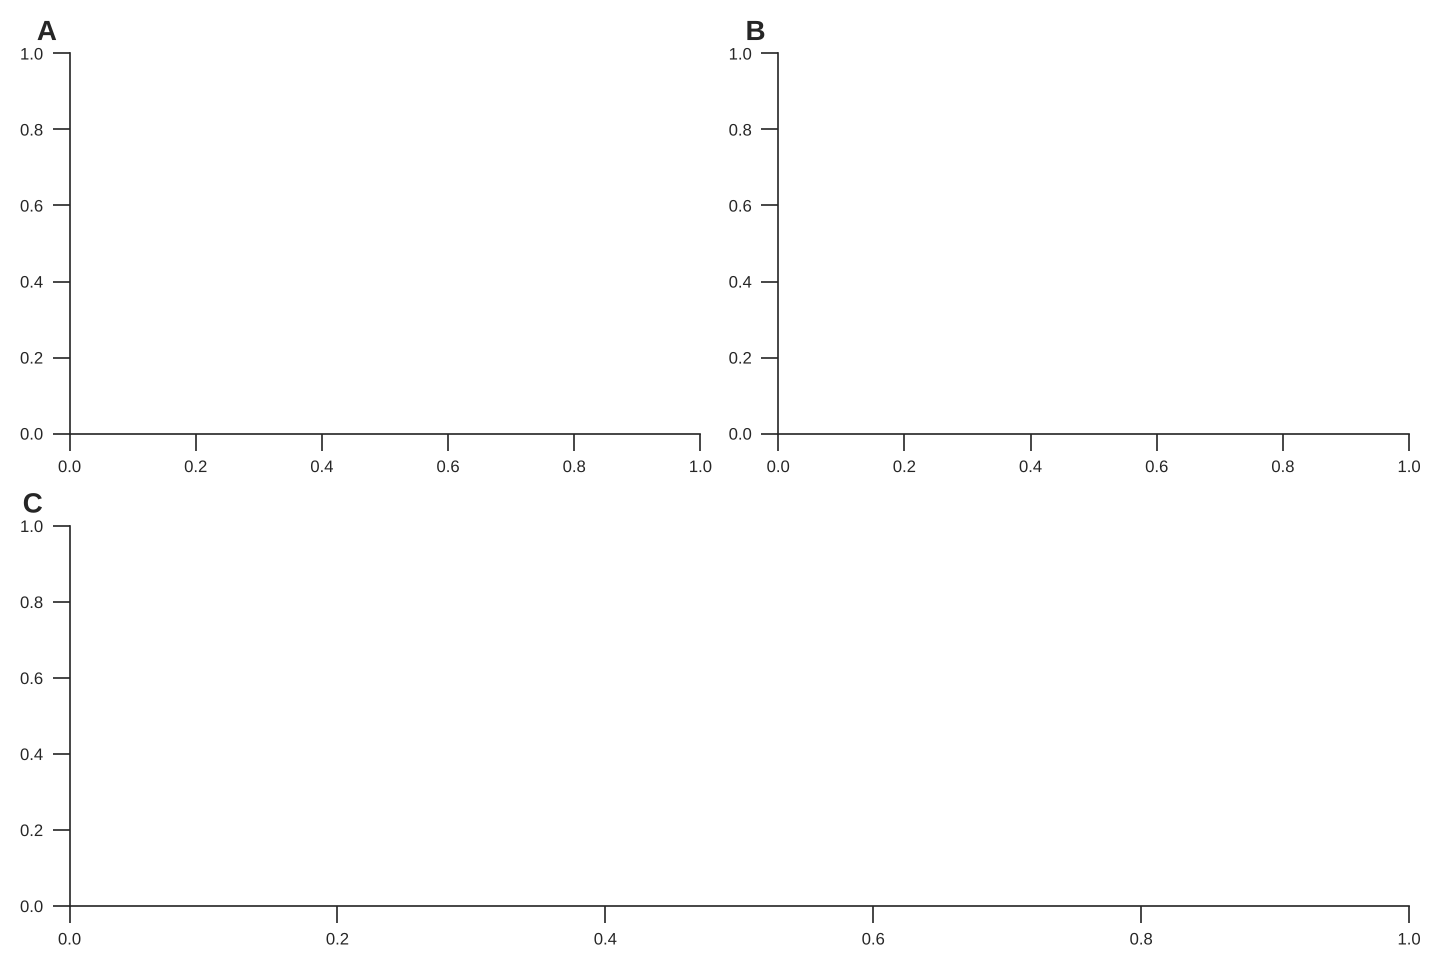

In [51]:
# Step 1 – empty layout with panel labels
fig, axd = plt.subplot_mosaic("AB;CC", figsize=(180 * MM, 120 * MM), layout="constrained")
for label, ax in axd.items():
    ax.text(-0.02, 1.02, label, transform=ax.transAxes, fontsize=10, fontweight="bold", ha="right", va="bottom")
plt.show()

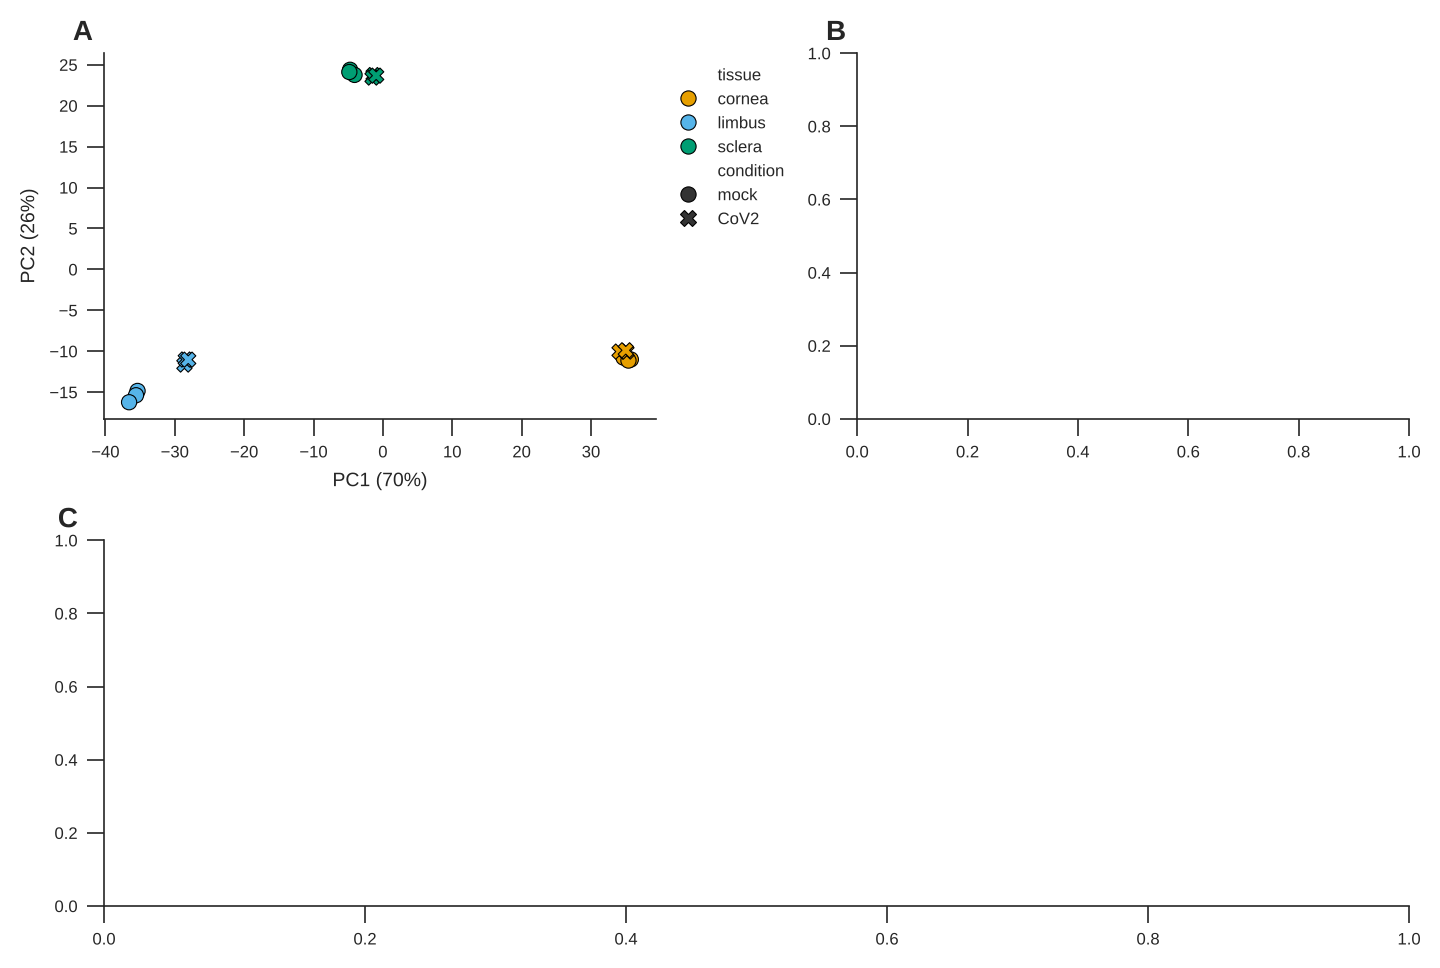

In [52]:
# Step 2 – panel A: PCA
sns.scatterplot(data=emb, x="PC1", y="PC2", hue="tissue", style="condition", palette=TISSUE_COLORS,
                hue_order=TISSUE_ORDER, style_order=CONDITION_ORDER, s=30, edgecolor="black",
                linewidth=0.4, ax=axd["A"])
axd["A"].set(xlabel=f"PC1 ({var_exp[0]:.0f}%)", ylabel=f"PC2 ({var_exp[1]:.0f}%)")
sns.move_legend(axd["A"], "upper left", bbox_to_anchor=(1, 1), frameon=False, title=None)
fig

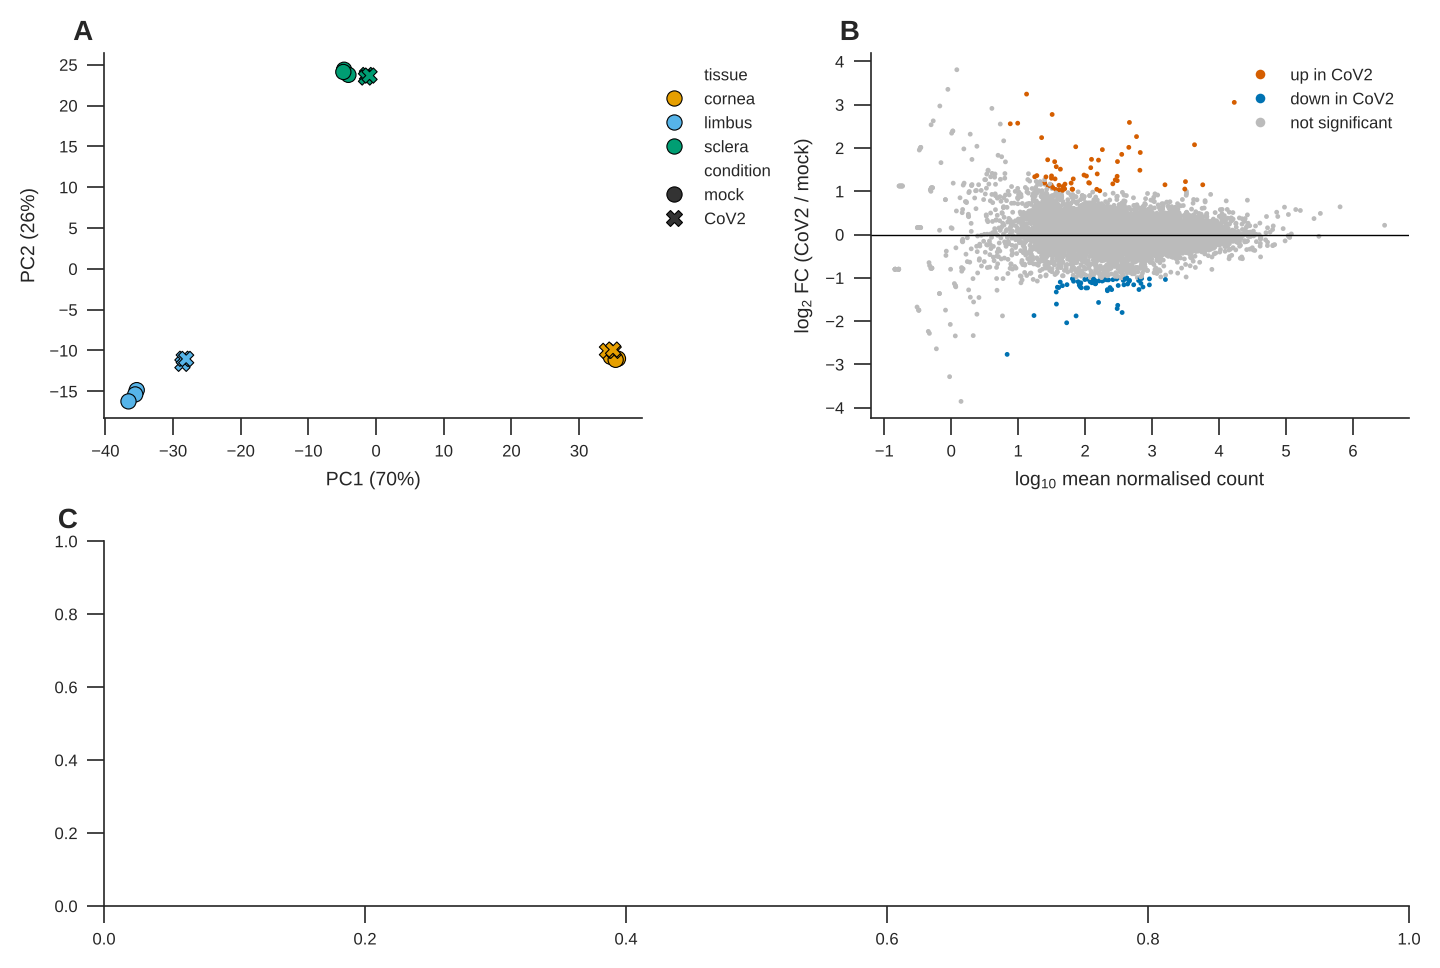

In [53]:
# Step 3 – panel B: MA plot
de["log10_baseMean"] = np.log10(de["baseMean"])
sns.scatterplot(data=de, x="log10_baseMean", y="log2FoldChange", hue="status", palette=DE_COLORS,
                hue_order=list(DE_COLORS), s=3, linewidth=0, rasterized=True, ax=axd["B"])
axd["B"].axhline(0, color="black", lw=0.5)
axd["B"].set(xlabel="log$_{10}$ mean normalised count", ylabel="log$_2$ FC (CoV2 / mock)")
axd["B"].legend(frameon=False, markerscale=2)
fig

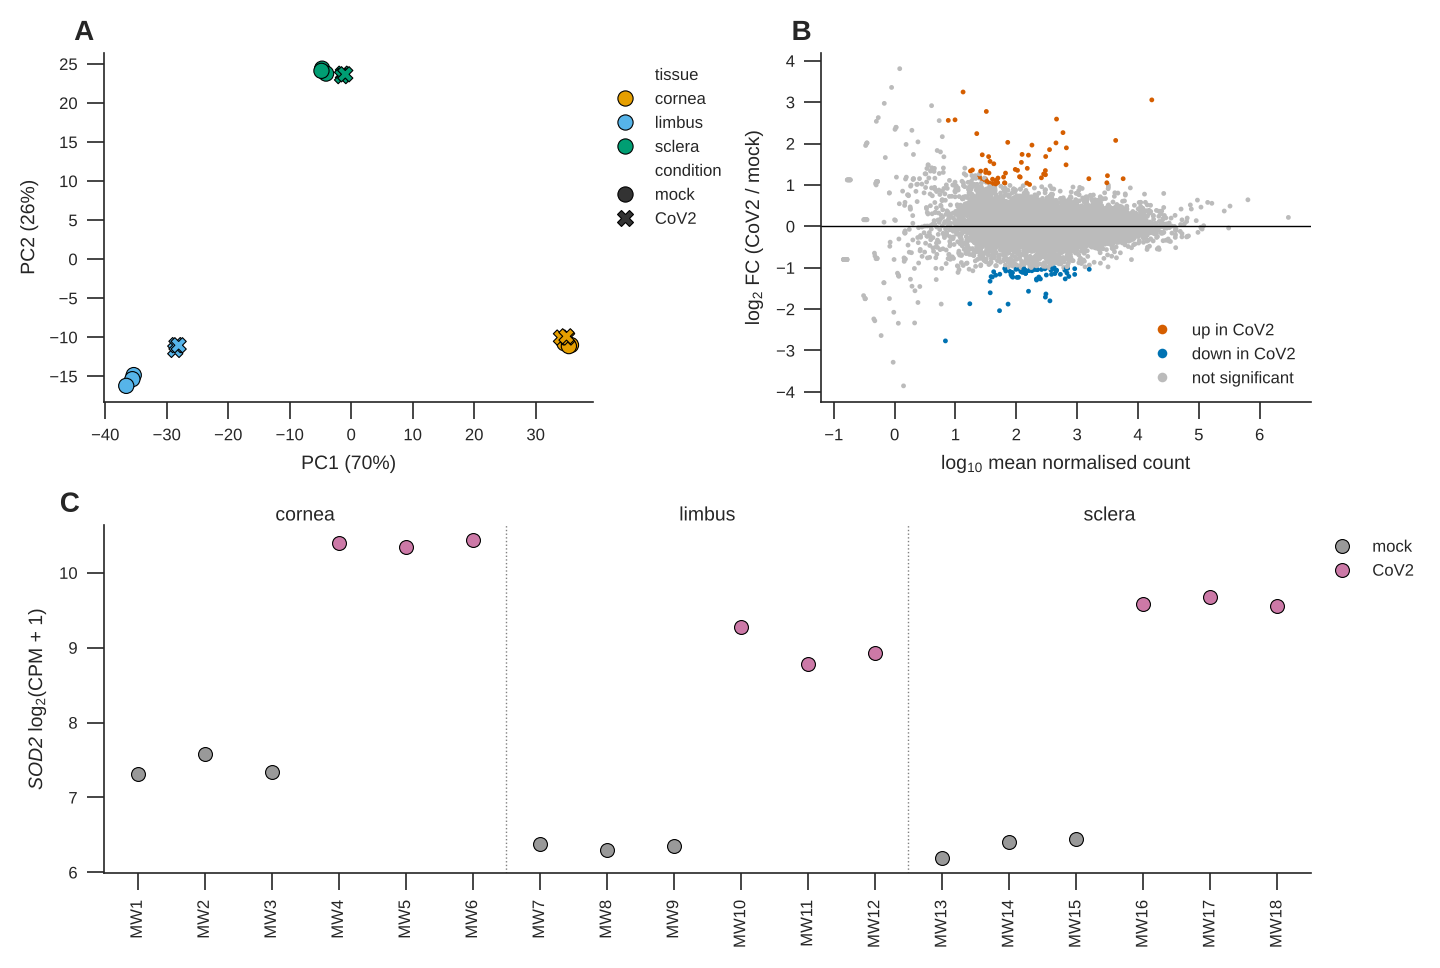

In [54]:
# Step 4 – panel C: SOD2 in every sample
df = expr_long[expr_long["gene"] == "SOD2"]
sns.stripplot(data=df, x="sample", y="log2cpm", hue="condition", palette=CONDITION_COLORS,
              hue_order=CONDITION_ORDER, size=5, edgecolor="black", linewidth=0.4, ax=axd["C"])
for i, t in enumerate(TISSUE_ORDER):                # tissue labels above each group of 6 samples
    axd["C"].text(i * 6 + 2.5, 1.0, t, transform=axd["C"].get_xaxis_transform(), ha="center", va="bottom")
    if i:
        axd["C"].axvline(i * 6 - 0.5, color="grey", lw=0.5, ls=":")
axd["C"].set(xlabel="", ylabel="$\\it{SOD2}$ log$_2$(CPM + 1)")
axd["C"].tick_params(axis="x", rotation=90)
sns.move_legend(axd["C"], "upper left", bbox_to_anchor=(1, 1), frameon=False, title=None)
fig

In [55]:
# Step 5 – export (and download if you are on Colab)
fig.savefig(FIGS / "Exercise6.pdf")
fig.savefig(FIGS / "Exercise6.svg")
fig.savefig(FIGS / "Exercise6.png", dpi=600)
if using_colab:
    from google.colab import files
    files.download(str(FIGS / "Exercise6.svg"))

---
## Wrap-up: a publication-figure checklist

Before a figure goes into a manuscript, check that:

- [ ] Every axis has a **label with units**; gene names are *italic*.
- [ ] Colours mean the **same thing in every panel**, and are **colour-blind safe** (no red/green only, no rainbow `jet`).
- [ ] **Individual data points** are shown when *n* is small; *n* and error bars are defined in the legend.
- [ ] Bar charts start at **zero**; axis ranges are not chosen to exaggerate effects.
- [ ] Fonts are **≥ 6 pt at final print size**; the figure is created at the journal's **column width**.
- [ ] Saved as **vector (PDF/SVG)**; dense scatter layers are `rasterized=True`; raster copies at ≥ 300 dpi.
- [ ] Dimensionality-reduction parameters and **random seeds** are reported.
- [ ] The code that made the figure is saved (this notebook!) so it can be regenerated.

### Further resources
* [Matplotlib cheatsheets](https://matplotlib.org/cheatsheets/) · [Matplotlib gallery](https://matplotlib.org/stable/gallery/index.html)
* [Seaborn tutorial](https://seaborn.pydata.org/tutorial.html) · [Seaborn gallery](https://seaborn.pydata.org/examples/index.html)
* Rougier, Droettboom & Bourne (2014). [Ten simple rules for better figures](https://doi.org/10.1371/journal.pcbi.1003833). *PLoS Comput Biol*.
* Crameri, Shephard & Heron (2020). [The misuse of colour in science communication](https://doi.org/10.1038/s41467-020-19160-7). *Nat Commun*.
* [From Data to Viz](https://www.data-to-viz.com/) – which chart for which data?

*Workshop created as part of the McGill Initiative in Computational Medicine (QLS-MiCM).*